In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

data=pd.read_csv("dft-road-casualty-statistics-collision-last-5-years.csv")
data.head()

C:\Users\BANAPURAM VINAY TEJA\AppData\Local\Temp\ipykernel_28072\2135464607.py:5: DtypeWarning: Columns (0: collision_index, 1: collision_ref_no) have mixed types. Specify dtype option on import or set low_memory=False.
  data=pd.read_csv("dft-road-casualty-statistics-collision-last-5-years.csv")


,collision_index,collision_year,collision_ref_no,location_easting_osgr,location_northing_osgr,longitude,latitude,police_force,collision_severity,number_of_vehicles,...,carriageway_hazards_historic,carriageway_hazards,urban_or_rural_area,did_police_officer_attend_scene_of_accident,trunk_road_flag,lsoa_of_accident_location,enhanced_severity_collision,collision_injury_based,collision_adjusted_severity_serious,collision_adjusted_severity_slight
0,202417H105824,2024,17H105824,448628.0,533968.0,-1.24700,54.69840,17,2,2,...,-1,0,1,1,2,E01012005,7,1,1.0,0.0
1,202517M115025,2025,17M115025,452379.0,519038.0,-1.19147,54.56387,17,2,2,...,-1,0,1,1,2,E01012090,6,1,1.0,0.0
2,202517L306225,2025,17L306225,459273.0,523811.0,-1.08390,54.60600,17,3,2,...,-1,0,1,1,2,E01032560,3,1,0.0,1.0
3,202417S104724,2024,17S104724,440460.0,517548.0,-1.37599,54.55157,17,3,2,...,-1,0,2,1,1,E01012269,3,1,0.0,1.0
4,202517S106525,2025,17S106525,444331.0,518776.0,-1.31596,54.56228,17,2,2,...,-1,0,1,1,2,E01035199,7,1,1.0,0.0


In [3]:
data["collision_severity"].value_counts()
data["collision_severity"].value_counts(normalize=True) * 100

collision_severity
3    75.794909
2    22.735067
1     1.470024
Name: proportion, dtype: float64

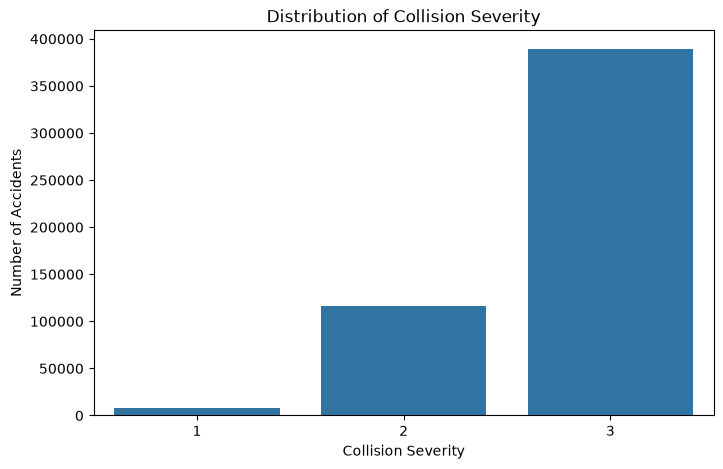

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
sns.countplot(
    data=data,
    x="collision_severity"
)
plt.title("Distribution of Collision Severity")
plt.xlabel("Collision Severity")
plt.ylabel("Number of Accidents")
plt.show()

In [5]:
missing = (data.isnull().mean() * 100).sort_values(
    ascending=False
)

print(missing)
data.isnull().sum()

location_easting_osgr                               0.010315
latitude                                            0.010315
longitude                                           0.010315
location_northing_osgr                              0.010315
collision_ref_no                                    0.000000
collision_year                                      0.000000
collision_index                                     0.000000
police_force                                        0.000000
collision_severity                                  0.000000
number_of_vehicles                                  0.000000
number_of_casualties                                0.000000
date                                                0.000000
day_of_week                                         0.000000
time                                                0.000000
local_authority_district                            0.000000
local_authority_ons_district                        0.000000
local_authority_highway 

collision_index                                      0
collision_year                                       0
collision_ref_no                                     0
location_easting_osgr                               53
location_northing_osgr                              53
longitude                                           53
latitude                                            53
police_force                                         0
collision_severity                                   0
number_of_vehicles                                   0
number_of_casualties                                 0
date                                                 0
day_of_week                                          0
time                                                 0
local_authority_district                             0
local_authority_ons_district                         0
local_authority_highway                              0
local_authority_highway_current                      0
first_road

In [6]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 513801 entries, 0 to 513800
Data columns (total 44 columns):
 #   Column                                            Non-Null Count   Dtype  
---  ------                                            --------------   -----  
 0   collision_index                                   513801 non-null  object 
 1   collision_year                                    513801 non-null  int64  
 2   collision_ref_no                                  513801 non-null  object 
 3   location_easting_osgr                             513748 non-null  float64
 4   location_northing_osgr                            513748 non-null  float64
 5   longitude                                         513748 non-null  float64
 6   latitude                                          513748 non-null  float64
 7   police_force                                      513801 non-null  int64  
 8   collision_severity                                513801 non-null  int64  
 9   number_of_vehic

In [7]:
categorical_cols = [
    "weather_conditions",
    "light_conditions",
    "road_surface_conditions",
    "road_type",
    "urban_or_rural_area",
    "junction_detail",
    "junction_control"
]

for col in categorical_cols:
    print(f"\n{col}")
    print(data[col].value_counts().head(10))


weather_conditions
weather_conditions
 1    413632
 2     55834
 8     15955
 9     14566
 5      5173
 4      4472
 7      2128
 3      1791
 6       238
-1        12
Name: count, dtype: int64

light_conditions
light_conditions
 1    368193
 4    105834
 6     27438
 7      8596
 5      3706
-1        34
Name: count, dtype: int64

road_surface_conditions
road_surface_conditions
 1    374268
 2    120572
 9      6721
 4      6668
-1      3527
 3      1257
 5       788
Name: count, dtype: int64

road_type
road_type
6    373065
3     76119
1     31178
9     13060
2     11550
7      8829
Name: count, dtype: int64

urban_or_rural_area
urban_or_rural_area
 1    345314
 2    168429
 3        50
-1         8
Name: count, dtype: int64

junction_detail
junction_detail
 0     252021
 13    142597
 16     47572
 19     31096
-1      19982
 18     11147
 17      7957
 99      1429
Name: count, dtype: int64

junction_control
junction_control
 4    222569
-1    217897
 2     56431
 9     11210
 3  

In [8]:
data["collision_year"].value_counts().sort_index()

collision_year
2021    101087
2022    106004
2023    104258
2024    100927
2025    101525
Name: count, dtype: int64

In [9]:
data.groupby("collision_year")["weather_conditions"].unique()

collision_year
2021    [-1, 1, 9, 2, 7, 4, 5, 3, 8, 6]
2022        [1, 2, 7, 4, 8, 9, 6, 5, 3]
2023        [1, 4, 3, 2, 9, 8, 7, 5, 6]
2024        [1, 9, 2, 4, 5, 7, 8, 3, 6]
2025        [1, 6, 2, 8, 7, 5, 9, 3, 4]
Name: weather_conditions, dtype: object

In [10]:
data[data["weather_conditions"] == -1][
    "collision_year"
].value_counts()

collision_year
2021    12
Name: count, dtype: int64

In [11]:
data.loc[
    data["weather_conditions"] == -1,
    ["collision_year", "weather_conditions", "collision_severity"]
]

,collision_year,weather_conditions,collision_severity
8863,2021,-1,3
230220,2021,-1,1
316085,2021,-1,3
328151,2021,-1,1
335547,2021,-1,3
350095,2021,-1,3
372152,2021,-1,3
397239,2021,-1,3
437968,2021,-1,3
438111,2021,-1,3


In [12]:
weather_map = {
    1: "Fine without high winds",
    2: "Raining without high winds",
    3: "Snowing without high winds",
    4: "Fine with high winds",
    5: "Raining with high winds",
    6: "Snowing with high winds",
    7: "Fog or mist",
    8: "Other",
    9: "Unknown"
}

In [13]:
data["weather_conditions"].map(weather_map).value_counts()

weather_conditions
Fine without high winds       413632
Raining without high winds     55834
Other                          15955
Unknown                        14566
Raining with high winds         5173
Fine with high winds            4472
Fog or mist                     2128
Snowing without high winds      1791
Snowing with high winds          238
Name: count, dtype: int64

In [14]:
data.groupby("collision_year")["light_conditions"].unique()

collision_year
2021    [-1, 1, 4, 6, 5, 7]
2022    [1, 6, 4, 5, 7, -1]
2023        [1, 6, 4, 7, 5]
2024    [1, 4, 6, 5, 7, -1]
2025    [4, 1, 6, 7, 5, -1]
Name: light_conditions, dtype: object

In [15]:
data[data["light_conditions"] == -1][
    "collision_year"
].value_counts().sort_index()

collision_year
2021    11
2022     1
2024     6
2025    16
Name: count, dtype: int64

In [16]:
light_map = {
    1: "Daylight",
    4: "Darkness - street lights lit",
    5: "Darkness - street lights unlit",
    6: "Darkness - no street lighting",
    7: "Darkness - lighting unknown"
}

In [17]:
data["light_conditions"].map(light_map).value_counts()

light_conditions
Daylight                          368193
Darkness - street lights lit      105834
Darkness - no street lighting      27438
Darkness - lighting unknown         8596
Darkness - street lights unlit      3706
Name: count, dtype: int64

In [18]:
data.groupby("collision_year")["road_surface_conditions"].unique()

collision_year
2021    [-1, 1, 2, 4, 3, 9, 5]
2022    [1, 2, 4, -1, 9, 3, 5]
2023    [1, 2, -1, 4, 9, 3, 5]
2024    [1, 2, 3, 4, -1, 5, 9]
2025    [1, 2, 4, 9, -1, 3, 5]
Name: road_surface_conditions, dtype: object

In [19]:
data[data["road_surface_conditions"] == -1][
    "collision_year"
].value_counts().sort_index()

collision_year
2021     431
2022     694
2023    1064
2024     704
2025     634
Name: count, dtype: int64

In [20]:
data[
    data["road_surface_conditions"].isin([6, 7])
][["collision_year", "road_surface_conditions"]].value_counts().sort_index()

Series([], Name: count, dtype: int64)

In [21]:
data[data["road_surface_conditions"] == 9][
    "collision_year"
].value_counts().sort_index()

collision_year
2021    1024
2022    1068
2023    1617
2024    1670
2025    1342
Name: count, dtype: int64

In [22]:

road_surface_map = {
    1: "Dry",
    2: "Wet or Damp",
    3: "Snow",
    4: "Frost or Ice",
    5: "Flood",
    9: "Unknown"
}

In [23]:
data["road_surface_conditions"].map(road_surface_map).value_counts()

road_surface_conditions
Dry             374268
Wet or Damp     120572
Unknown           6721
Frost or Ice      6668
Snow              1257
Flood              788
Name: count, dtype: int64

In [24]:
data.groupby("collision_year")["road_type"].unique()

collision_year
2021    [3, 9, 6, 2, 7, 1]
2022    [6, 3, 1, 7, 2, 9]
2023    [6, 3, 9, 1, 7, 2]
2024    [6, 3, 1, 7, 2, 9]
2025    [6, 1, 7, 3, 2, 9]
Name: road_type, dtype: object

In [25]:
road_type_map = {
    1: "Roundabout",
    2: "One-way street",
    3: "Dual carriageway",
    6: "Single carriageway",
    7: "Slip road",
    9: "Unknown"
}

In [26]:
data["road_type"].map(road_type_map).value_counts().sort_index()

road_type
Dual carriageway       76119
One-way street         11550
Roundabout             31178
Single carriageway    373065
Slip road               8829
Unknown                13060
Name: count, dtype: int64

In [27]:
data.groupby("collision_year")["junction_detail"].unique()

collision_year
2021        [-1, 0, 13, 16, 17, 18, 19]
2022        [0, 13, 16, 17, 18, 19, -1]
2023        [-1, 0, 13, 16, 17, 18, 19]
2024    [0, 19, -1, 13, 16, 18, 17, 99]
2025    [13, -1, 0, 19, 16, 17, 18, 99]
Name: junction_detail, dtype: object

In [28]:
data[data["junction_detail"] == -1][
    "collision_year"
].value_counts().sort_index()

collision_year
2021    2061
2022    1817
2023    2398
2024    7005
2025    6701
Name: count, dtype: int64

In [29]:
data[data["junction_detail"] == 99][
    "collision_year"
].value_counts().sort_index()

collision_year
2024       2
2025    1427
Name: count, dtype: int64

In [30]:
data.groupby("collision_year")["junction_detail"].value_counts().sort_index()

collision_year  junction_detail
2021            -1                  2061
                 0                 52176
                 13                27699
                 16                 9371
                 17                 1520
                 18                 2209
                 19                 6051
2022            -1                  1817
                 0                 55139
                 13                29657
                 16                 9743
                 17                 1630
                 18                 2275
                 19                 5743
2023            -1                  2398
                 0                 53234
                 13                29039
                 16                 9507
                 17                 1634
                 18                 2263
                 19                 6183
2024            -1                  7005
                 0                 46139
                 13      

In [31]:
junction_detail_map = {
    -1: "Data missing or out of range",
    0: "Not at or within 20 metres of junction",
    13: "T or staggered junction",
    16: "Crossroads",
    17: "Junction with more than four arms",
    18: "Using private drive or entrance",
    19: "Other junction",
    99: "Unknown - self reported"
}

In [32]:
data["junction_detail"].map(junction_detail_map).value_counts().sort_index()

junction_detail
Crossroads                                 47572
Data missing or out of range               19982
Junction with more than four arms           7957
Not at or within 20 metres of junction    252021
Other junction                             31096
T or staggered junction                   142597
Unknown - self reported                     1429
Using private drive or entrance            11147
Name: count, dtype: int64

In [33]:
data.groupby("collision_year")["junction_control"].unique()

collision_year
2021    [-1, 2, 4, 1, 3, 9]
2022    [-1, 4, 2, 1, 3, 9]
2023    [-1, 4, 2, 3, 1, 9]
2024    [-1, 2, 4, 3, 9, 1]
2025    [4, -1, 2, 9, 3, 1]
Name: junction_control, dtype: object

In [34]:
data[data["junction_control"] == -1][
    "collision_year"
].value_counts().sort_index()

collision_year
2021    42057
2022    44977
2023    43795
2024    42581
2025    44487
Name: count, dtype: int64

In [35]:
data[data["junction_control"] == 9][
    "collision_year"
].value_counts().sort_index()

collision_year
2021    1890
2022    1662
2023    2224
2024    1908
2025    3526
Name: count, dtype: int64

In [36]:
data.loc[
    data["junction_control"] == -1,
    "junction_detail"
].value_counts().sort_index()

junction_detail
-1        447
 0     213958
 13      1397
 16       259
 17        74
 18       666
 19      1053
 99        43
Name: count, dtype: int64

In [37]:
data.loc[
    (data["junction_control"] == -1) &
    (data["junction_detail"] != 0),
    ["collision_year", "junction_detail", "junction_control"]
].value_counts().sort_index()

collision_year  junction_detail  junction_control
2021            -1               -1                    1
                 13              -1                  183
                 16              -1                   27
                 17              -1                    8
                 18              -1                   76
                 19              -1                  108
2022             13              -1                  258
                 16              -1                   35
                 17              -1                   17
                 18              -1                  102
                 19              -1                  168
2023            -1               -1                    1
                 13              -1                  314
                 16              -1                   49
                 17              -1                   14
                 18              -1                  122
                 19              -1   

In [38]:
pd.crosstab(
    data["junction_detail"],
    data["junction_control"]
)

junction_control,-1,1,2,3,4,9
junction_detail,,,,,,
-1,447,91,2592,146,9727,6979
0,213958,260,5498,200,31782,323
13,1397,988,16415,1514,120947,1336
16,259,290,22313,1118,23301,291
17,74,114,4247,90,3406,26
18,666,74,239,35,9795,338
19,1053,391,4943,371,23500,838
99,43,2,184,10,111,1079


In [39]:
junction_control_map = {
    -1: "Missing or out of range",
    1: "Authorised person",
    2: "Automatic traffic signal",
    3: "Stop sign",
    4: "Give way or uncontrolled",
    9: "Unknown"
}

In [40]:
data["junction_control"].map(
    junction_control_map
).value_counts()

junction_control
Give way or uncontrolled    222569
Missing or out of range     217897
Automatic traffic signal     56431
Unknown                      11210
Stop sign                     3484
Authorised person             2210
Name: count, dtype: int64

In [41]:
data.groupby("collision_year")["urban_or_rural_area"].unique()

collision_year
2021        [1, 2, 3]
2022        [1, 2, 3]
2023    [1, 2, -1, 3]
2024        [1, 2, 3]
2025        [1, 2, 3]
Name: urban_or_rural_area, dtype: object

In [42]:
data[data["urban_or_rural_area"] == -1][
    "collision_year"
].value_counts().sort_index()

collision_year
2023    8
Name: count, dtype: int64

In [43]:
data = data[data["urban_or_rural_area"] != -1]

In [44]:
data["urban_or_rural_area"].value_counts()

urban_or_rural_area
1    345314
2    168429
3        50
Name: count, dtype: int64

In [45]:
urban_rural_map = {
    1: "Urban area",
    2: "Small town",
    3: "Rural area"
}

In [46]:
data["urban_or_rural_area"].map(urban_rural_map).value_counts().sort_index()

urban_or_rural_area
Rural area        50
Small town    168429
Urban area    345314
Name: count, dtype: int64

In [47]:
data.groupby("collision_year")["pedestrian_crossing"].unique()

collision_year
2021    [-1, 0, 14, 13, 11, 99, 15, 12, 17, 16]
2022    [0, 14, 15, 13, -1, 11, 17, 99, 16, 12]
2023    [0, 14, 99, 13, -1, 15, 17, 12, 11, 16]
2024    [0, 14, 17, 13, 15, 16, -1, 12, 11, 99]
2025    [0, -1, 15, 13, 14, 16, 17, 12, 11, 99]
Name: pedestrian_crossing, dtype: object

In [48]:
data[data["pedestrian_crossing"] == -1][
    "collision_year"
].value_counts().sort_index()

collision_year
2021     225
2022     684
2023    2768
2024    1034
2025    6527
Name: count, dtype: int64

In [49]:
data[data["pedestrian_crossing"] == 99][
    "collision_year"
].value_counts().sort_index()

collision_year
2021    2395
2022    2434
2023    4510
2024    3012
2025     301
Name: count, dtype: int64

In [50]:
pedestrian_map = {
    -1: "Missing or out of range",
    0: "No physical crossing facility within 50 metres",
    11: "School crossing patrol",
    12: "Other authorised person controlling crossing",
    13: "Zebra crossing",
    14: "Pedestrian light crossing",
    15: "Pedestrian phase at traffic signal",
    16: "Footbridge or subway",
    17: "Central refuge",
    99: "Unknown - self reported"
}

In [51]:
data["pedestrian_crossing"].map(pedestrian_map).value_counts().sort_index()

pedestrian_crossing
Central refuge                                     13095
Footbridge or subway                                1200
Missing or out of range                            11238
No physical crossing facility within 50 metres    381387
Other authorised person controlling crossing        5474
Pedestrian light crossing                          29782
Pedestrian phase at traffic signal                 36371
School crossing patrol                              1994
Unknown - self reported                            12652
Zebra crossing                                     20600
Name: count, dtype: int64

In [52]:
data.groupby("collision_year")["special_conditions_at_site"].unique()

collision_year
2021    [1, 0, 4, 5, 9, -1, 7, 2, 6, 3]
2022    [0, -1, 4, 5, 1, 9, 7, 6, 3, 2]
2023    [0, 9, 4, -1, 1, 5, 6, 7, 2, 3]
2024    [-1, 0, 9, 4, 3, 1, 5, 6, 7, 2]
2025    [-1, 0, 5, 4, 7, 1, 6, 9, 3, 2]
Name: special_conditions_at_site, dtype: object

In [53]:
data[data["special_conditions_at_site"] == -1][
    "collision_year"
].value_counts().sort_index()

collision_year
2021      351
2022      746
2023     3116
2024    59299
2025    87858
Name: count, dtype: int64

In [54]:
data[data["special_conditions_at_site"] == 9][
    "collision_year"
].value_counts().sort_index()

collision_year
2021    1774
2022    1917
2023    3969
2024    2672
2025     226
Name: count, dtype: int64

In [55]:
data.loc[
    data["special_conditions_at_site"] == -1,
    [
        "collision_year",
        "special_conditions_at_site",
        "carriageway_hazards",
        "carriageway_hazards_historic",
        "road_surface_conditions"
    ]
].head(15)

,collision_year,special_conditions_at_site,carriageway_hazards,carriageway_hazards_historic,road_surface_conditions
0,2024,-1,0,-1,1
1,2025,-1,0,-1,1
2,2025,-1,0,-1,1
3,2024,-1,0,-1,1
4,2025,-1,0,-1,1
5,2025,-1,0,-1,1
6,2025,-1,0,-1,1
7,2024,-1,0,-1,1
8,2024,-1,0,-1,1
9,2025,-1,0,-1,1


In [56]:
data.loc[
    data["special_conditions_at_site"] == -1
].groupby(
    ["collision_year", "carriageway_hazards"]
).size().unstack(fill_value=0)

carriageway_hazards,-1,0,11,12,13,14,15,16,17,18,19,20,21,99
collision_year,,,,,,,,,,,,,,
2021,325,24,0,0,0,0,0,0,1,0,0,1,0,0
2022,713,32,0,0,0,0,0,0,0,0,0,1,0,0
2023,3086,28,0,0,0,0,0,0,1,0,1,0,0,0
2024,421,55631,150,131,730,82,227,103,650,132,104,165,238,535
2025,5346,78381,235,227,902,115,288,96,777,146,133,205,472,535


In [57]:
data.groupby("collision_year")[
    "carriageway_hazards"
].unique()

collision_year
2021    [11, 0, 13, 21, 16, 99, 17, -1, 15, 19, 20, 18...
2022    [0, 19, -1, 13, 16, 20, 21, 11, 99, 17, 15, 18...
2023    [0, 99, 13, -1, 11, 16, 21, 20, 19, 17, 18, 14...
2024    [0, 17, 13, 20, 19, 21, -1, 99, 18, 15, 11, 16...
2025    [0, 17, 11, -1, 12, 13, 21, 99, 18, 15, 20, 19...
Name: carriageway_hazards, dtype: object

In [58]:
data.groupby(
    ["collision_year", "carriageway_hazards"]
).size().unstack(fill_value=0)

carriageway_hazards,-1,0,11,12,13,14,15,16,17,18,19,20,21,99
collision_year,,,,,,,,,,,,,,
2021,325,95154,370,157,1410,130,203,236,1015,172,189,342,248,1136
2022,713,99640,351,173,1225,122,213,240,1017,170,235,333,224,1348
2023,3086,93626,342,156,1225,116,258,239,934,196,224,275,242,3331
2024,421,93522,310,209,1196,124,305,199,943,191,249,265,331,2662
2025,5346,91375,277,243,1042,123,318,123,881,164,161,271,506,695


In [59]:
data.groupby("collision_year")[
    "carriageway_hazards_historic"
].value_counts()

collision_year  carriageway_hazards_historic
2021             0                               97076
                 9                                1487
                 2                                1185
                 7                                 348
                -1                                 342
                 1                                 262
                 6                                 202
                 3                                 185
2022             0                              101449
                 9                                1638
                 2                                1159
                -1                                 746
                 7                                 339
                 1                                 249
                 6                                 244
                 3                                 180
2023             0                               95423
                 9  

In [60]:
pd.crosstab(
    data.loc[
        data["carriageway_hazards_historic"] != -1,
        "carriageway_hazards_historic"
    ],
    data.loc[
        data["carriageway_hazards_historic"] != -1,
        "carriageway_hazards"
    ]
)

carriageway_hazards,0,11,12,13,14,15,16,17,18,19,20,21,99
carriageway_hazards_historic,,,,,,,,,,,,,
0,338195,1131,512,3978,375,724,0,0,0,0,0,708,0
1,0,31,6,12,7,6,838,0,0,0,0,8,0
2,0,30,24,355,25,22,0,3363,0,0,0,81,0
3,0,11,7,13,5,0,0,0,615,0,0,5,0
6,0,13,4,26,0,2,0,0,0,821,0,2,0
7,0,3,1,0,1,8,0,0,0,0,1116,4,0
9,1032,43,26,77,5,20,0,0,0,0,0,33,8102


In [61]:
pd.crosstab(
    data.loc[
        (data["collision_year"].isin([2021, 2022, 2023])) &
        (data["carriageway_hazards_historic"] != -1),
        "carriageway_hazards_historic"
    ],
    data.loc[
        (data["collision_year"].isin([2021, 2022, 2023])) &
        (data["carriageway_hazards_historic"] != -1),
        "carriageway_hazards"
    ]
)

carriageway_hazards,0,11,12,13,14,15,16,17,18,19,20,21,99
carriageway_hazards_historic,,,,,,,,,,,,,
0,287545,949,435,3464,330,622,0,0,0,0,0,603,0
1,0,28,6,12,7,5,715,0,0,0,0,8,0
2,0,28,20,287,23,20,0,2966,0,0,0,71,0
3,0,10,6,11,5,0,0,0,538,0,0,4,0
6,0,12,1,21,0,2,0,0,0,648,0,2,0
7,0,3,1,0,1,8,0,0,0,0,950,4,0
9,791,31,17,60,2,17,0,0,0,0,0,22,5815


In [62]:
data.loc[
    data["collision_year"].isin([2021, 2022, 2023]),
    [
        "collision_year",
        "carriageway_hazards_historic",
        "special_conditions_at_site",
        "road_surface_conditions",
        "carriageway_hazards"
    ]
].head(20)

,collision_year,carriageway_hazards_historic,special_conditions_at_site,road_surface_conditions,carriageway_hazards
8863,2021,1,1,-1,11
117440,2023,0,0,1,0
125669,2021,0,0,1,0
147476,2021,0,0,1,0
147477,2022,0,0,1,0
147478,2023,0,0,1,0
147479,2023,0,0,1,0
147480,2023,0,0,1,0
147481,2021,0,0,1,0
147482,2022,0,0,1,0


In [63]:
data.loc[
    data["collision_year"].isin([2021, 2022, 2023])
].groupby(
    [
        "carriageway_hazards_historic",
        "special_conditions_at_site",
        "road_surface_conditions",
        "carriageway_hazards"
    ]
).size().reset_index(name="count").sort_values(
    "count", ascending=False
).head(30)

,carriageway_hazards_historic,special_conditions_at_site,road_surface_conditions,carriageway_hazards,count
19,0,0,1,0,212508
20,0,0,2,0,66535
22,0,0,4,0,3967
42,0,4,1,13,2603
211,9,9,1,99,2558
216,9,9,9,99,2270
95,2,0,1,17,1969
0,-1,-1,-1,-1,1633
1,-1,-1,1,-1,1222
64,0,9,1,0,1196


In [64]:
data.loc[
    data["collision_year"].isin([2021, 2022, 2023])
].groupby(
    [
        "carriageway_hazards_historic",
        "special_conditions_at_site",
        "road_surface_conditions"
    ]
)["carriageway_hazards"].nunique().sort_values(
    ascending=False
)

carriageway_hazards_historic  special_conditions_at_site  road_surface_conditions
-1                            -1                          -1                         1
                                                           1                         1
                                                           2                         1
                                                           3                         1
                                                           4                         1
                                                                                    ..
 9                             9                           2                         1
                                                           3                         1
                                                           4                         1
                                                           5                         1
                                                

In [65]:
data.groupby("collision_year")["carriageway_hazards"].unique()

collision_year
2021    [11, 0, 13, 21, 16, 99, 17, -1, 15, 19, 20, 18...
2022    [0, 19, -1, 13, 16, 20, 21, 11, 99, 17, 15, 18...
2023    [0, 99, 13, -1, 11, 16, 21, 20, 19, 17, 18, 14...
2024    [0, 17, 13, 20, 19, 21, -1, 99, 18, 15, 11, 16...
2025    [0, 17, 11, -1, 12, 13, 21, 99, 18, 15, 20, 19...
Name: carriageway_hazards, dtype: object

In [66]:
data["carriageway_hazards"].value_counts().sort_index()

carriageway_hazards
-1       9891
 0     473317
 11      1650
 12       938
 13      6098
 14       615
 15      1297
 16      1037
 17      4790
 18       893
 19      1058
 20      1486
 21      1551
 99      9172
Name: count, dtype: int64

In [67]:
carriageway_hazards_map = {
    -1: "Missing or out of range",
     0: "None",
    11: "Defective traffic signals",
    12: "Defective or obscured road signs or markings",
    13: "Roadworks",
    14: "Oil or diesel",
    15: "Mud",
    16: "Dislodged vehicle load",
    17: "Other object in carriageway",
    18: "Involvement with previous collision",
    19: "Pedestrian in carriageway",
    20: "Animal in carriageway",
    21: "Poor or defective road surface",
    99: "Unknown"
}

In [68]:
data["carriageway_hazards"] = (
    data["carriageway_hazards"].map(carriageway_hazards_map)
)

In [69]:
data["carriageway_hazards"].value_counts()

carriageway_hazards
None                                            473317
Missing or out of range                           9891
Unknown                                           9172
Roadworks                                         6098
Other object in carriageway                       4790
Defective traffic signals                         1650
Poor or defective road surface                    1551
Animal in carriageway                             1486
Mud                                               1297
Pedestrian in carriageway                         1058
Dislodged vehicle load                            1037
Defective or obscured road signs or markings       938
Involvement with previous collision                893
Oil or diesel                                      615
Name: count, dtype: int64

In [70]:
data.groupby("collision_year")["carriageway_hazards_historic"].unique()

collision_year
2021    [1, 0, 9, 2, -1, 6, 7, 3]
2022    [0, 6, -1, 1, 7, 9, 2, 3]
2023    [0, 9, 2, -1, 1, 6, 7, 3]
2024    [-1, 9, 0, 2, 3, 1, 7, 6]
2025    [-1, 0, 1, 2, 7, 6, 3, 9]
Name: carriageway_hazards_historic, dtype: object

In [71]:
carriageway_historic_map = {
    -1: "Missing or out of range",
     0: "None",
     1: "Dislodged vehicle load",
     2: "Other object in carriageway",
     3: "Involvement with previous accident",
     6: "Pedestrian in carriageway",
     7: "Animal in carriageway",
     9: "Unknown - verify code"
}

In [72]:
data["carriageway_hazards_historic"] = (
    data["carriageway_hazards_historic"]
    .map(carriageway_historic_map)
)

In [73]:
data["carriageway_hazards_historic"].value_counts()

carriageway_hazards_historic
None                                  345623
Missing or out of range               151367
Unknown - verify code                   9338
Other object in carriageway             3900
Animal in carriageway                   1133
Dislodged vehicle load                   908
Pedestrian in carriageway                868
Involvement with previous accident       656
Name: count, dtype: int64

In [74]:
special_conditions_map = {
    -1: "Missing or out of range",
     0: "None",
     1: "Automatic traffic signal out",
     2: "Automatic traffic signal partially defective",
     3: "Road signs or markings defective",
     4: "Roadworks",
     5: "Road surface defective",
     6: "Oil or diesel",
     7: "Mud",
     9: "Unknown - self reported"
}

In [75]:
data["special_conditions_at_site"] = (
    data["special_conditions_at_site"].map(special_conditions_map)
)

In [76]:
data["special_conditions_at_site"].value_counts(dropna=False)

special_conditions_at_site
None                                            343513
Missing or out of range                         151370
Unknown - self reported                          10558
Roadworks                                         4466
Automatic traffic signal out                      1081
Road surface defective                             841
Mud                                                782
Road signs or markings defective                   580
Oil or diesel                                      418
Automatic traffic signal partially defective       184
Name: count, dtype: int64

In [77]:
data.isnull().sum().sort_values(ascending=False).head(15)

location_easting_osgr       45
latitude                    45
longitude                   45
location_northing_osgr      45
collision_ref_no             0
collision_year               0
collision_index              0
police_force                 0
collision_severity           0
number_of_vehicles           0
number_of_casualties         0
date                         0
day_of_week                  0
time                         0
local_authority_district     0
dtype: int64

In [78]:
data[data["latitude"].isnull()][
    ["location_easting_osgr", "location_northing_osgr",
     "latitude", "longitude"]
]

,location_easting_osgr,location_northing_osgr,latitude,longitude
177440,NaN,NaN,NaN,NaN
179211,NaN,NaN,NaN,NaN
200583,NaN,NaN,NaN,NaN
211327,NaN,NaN,NaN,NaN
214603,NaN,NaN,NaN,NaN
216612,NaN,NaN,NaN,NaN
219826,NaN,NaN,NaN,NaN
224947,NaN,NaN,NaN,NaN
228283,NaN,NaN,NaN,NaN
230067,NaN,NaN,NaN,NaN


In [79]:
data = data.dropna(subset=["latitude"])

In [80]:
data.shape

(513748, 44)

In [81]:
data.duplicated().sum()

np.int64(0)

In [82]:
data.info()

<class 'pandas.DataFrame'>
Index: 513748 entries, 0 to 513800
Data columns (total 44 columns):
 #   Column                                            Non-Null Count   Dtype  
---  ------                                            --------------   -----  
 0   collision_index                                   513748 non-null  object 
 1   collision_year                                    513748 non-null  int64  
 2   collision_ref_no                                  513748 non-null  object 
 3   location_easting_osgr                             513748 non-null  float64
 4   location_northing_osgr                            513748 non-null  float64
 5   longitude                                         513748 non-null  float64
 6   latitude                                          513748 non-null  float64
 7   police_force                                      513748 non-null  int64  
 8   collision_severity                                513748 non-null  int64  
 9   number_of_vehicles  

In [83]:
(data["collision_severity"].value_counts(normalize=True).sort_index() * 100).round(2)

collision_severity
1     1.47
2    22.73
3    75.80
Name: proportion, dtype: float64

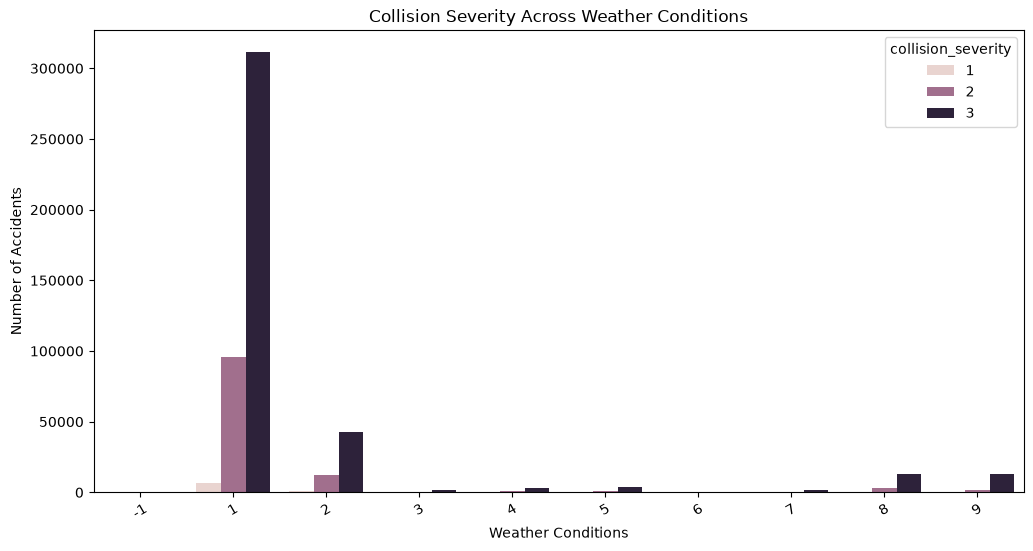

In [84]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=data,
    x="weather_conditions",
    hue="collision_severity"
)

plt.title("Collision Severity Across Weather Conditions")
plt.xlabel("Weather Conditions")
plt.ylabel("Number of Accidents")
plt.xticks(rotation=30)
plt.show()

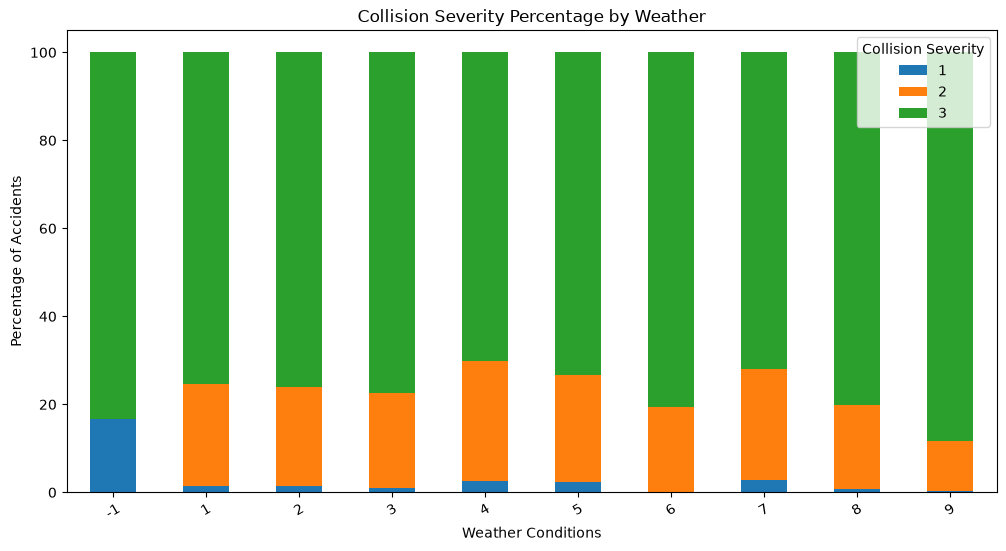

In [85]:
weather_severity = pd.crosstab(
    data["weather_conditions"],
    data["collision_severity"],
    normalize="index"
) * 100

weather_severity.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("Collision Severity Percentage by Weather")
plt.xlabel("Weather Conditions")
plt.ylabel("Percentage of Accidents")
plt.legend(title="Collision Severity")
plt.xticks(rotation=30)
plt.show()

In [86]:
data["weather_conditions"].value_counts().sort_index()

weather_conditions
-1        12
 1    413589
 2     55828
 3      1791
 4      4472
 5      5172
 6       238
 7      2127
 8     15954
 9     14565
Name: count, dtype: int64

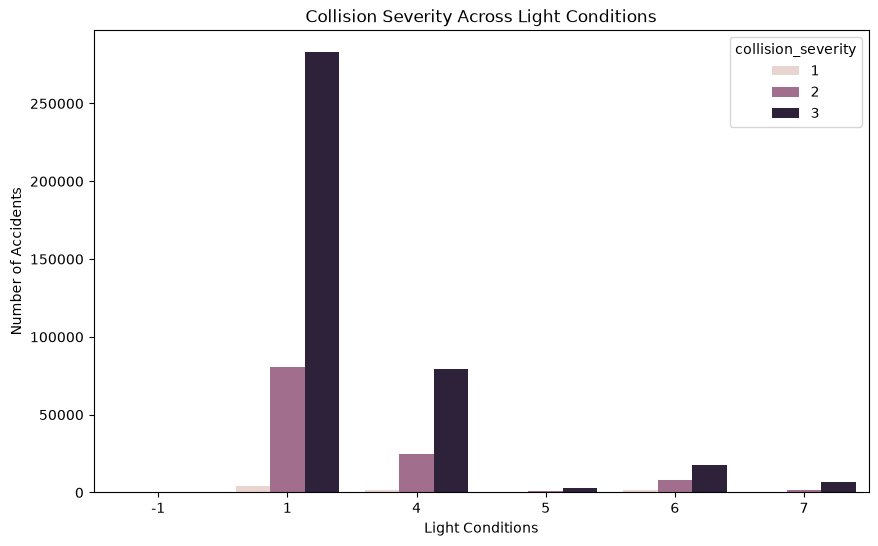

In [87]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=data,
    x="light_conditions",
    hue="collision_severity"
)

plt.title("Collision Severity Across Light Conditions")
plt.xlabel("Light Conditions")
plt.ylabel("Number of Accidents")
plt.show()

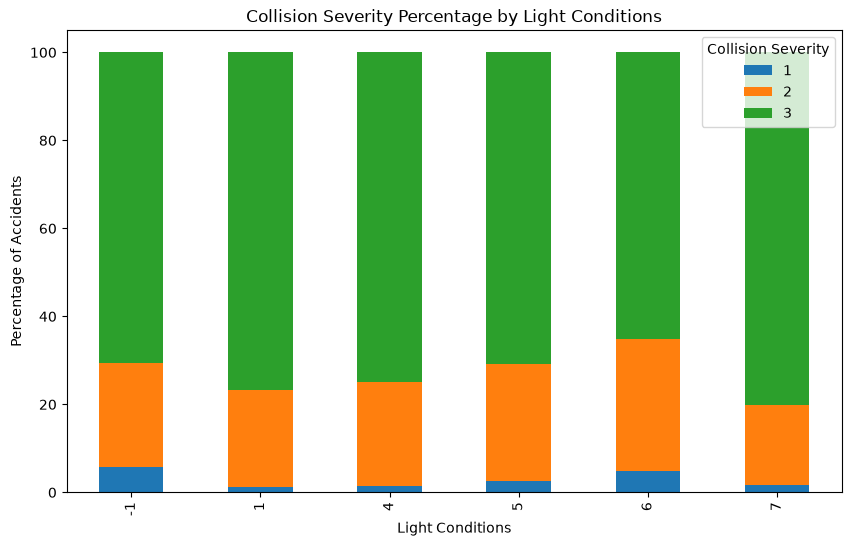

In [88]:
light_severity = pd.crosstab(
    data["light_conditions"],
    data["collision_severity"],
    normalize="index"
) * 100

light_severity.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("Collision Severity Percentage by Light Conditions")
plt.xlabel("Light Conditions")
plt.ylabel("Percentage of Accidents")
plt.legend(title="Collision Severity")
plt.show()

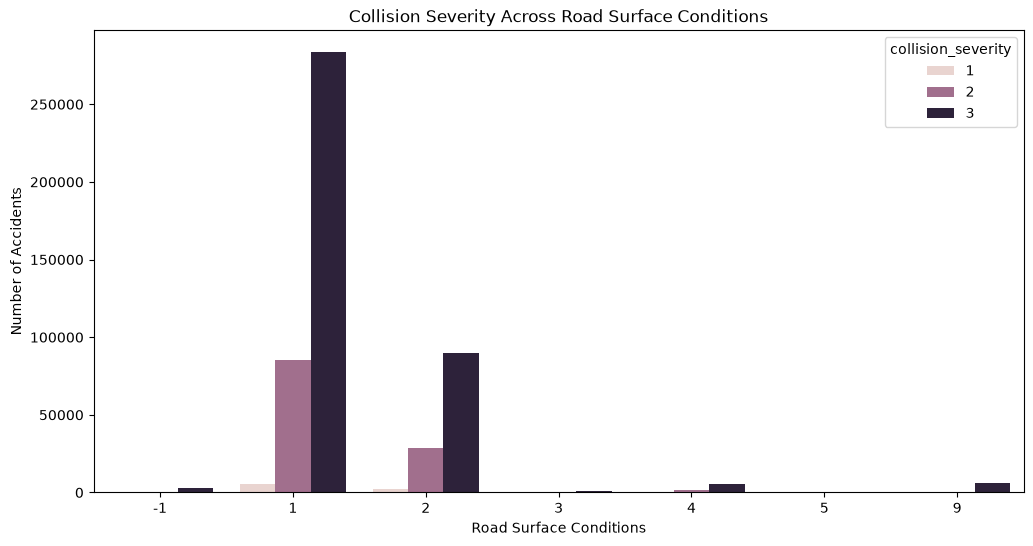

In [89]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=data,
    x="road_surface_conditions",
    hue="collision_severity"
)

plt.title("Collision Severity Across Road Surface Conditions")
plt.xlabel("Road Surface Conditions")
plt.ylabel("Number of Accidents")
plt.show()

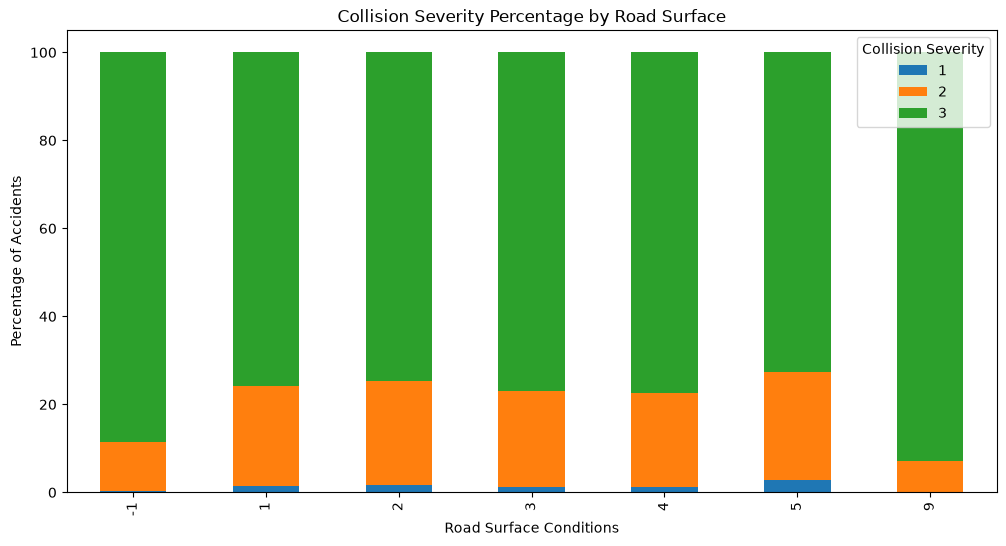

In [90]:
surface_severity = pd.crosstab(
    data["road_surface_conditions"],
    data["collision_severity"],
    normalize="index"
) * 100

surface_severity.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("Collision Severity Percentage by Road Surface")
plt.xlabel("Road Surface Conditions")
plt.ylabel("Percentage of Accidents")
plt.legend(title="Collision Severity")
plt.show()

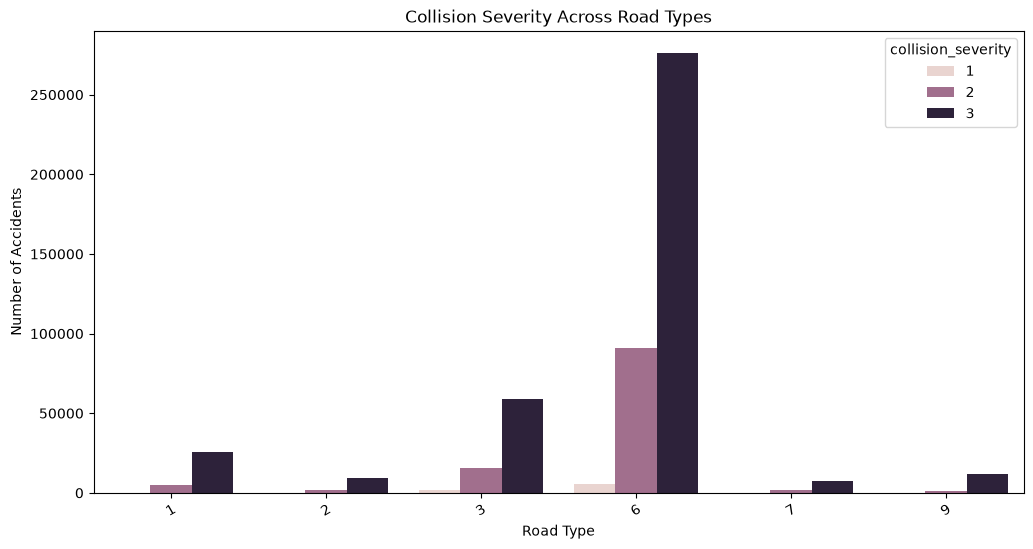

In [91]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=data,
    x="road_type",
    hue="collision_severity"
)

plt.title("Collision Severity Across Road Types")
plt.xlabel("Road Type")
plt.ylabel("Number of Accidents")
plt.xticks(rotation=30)
plt.show()

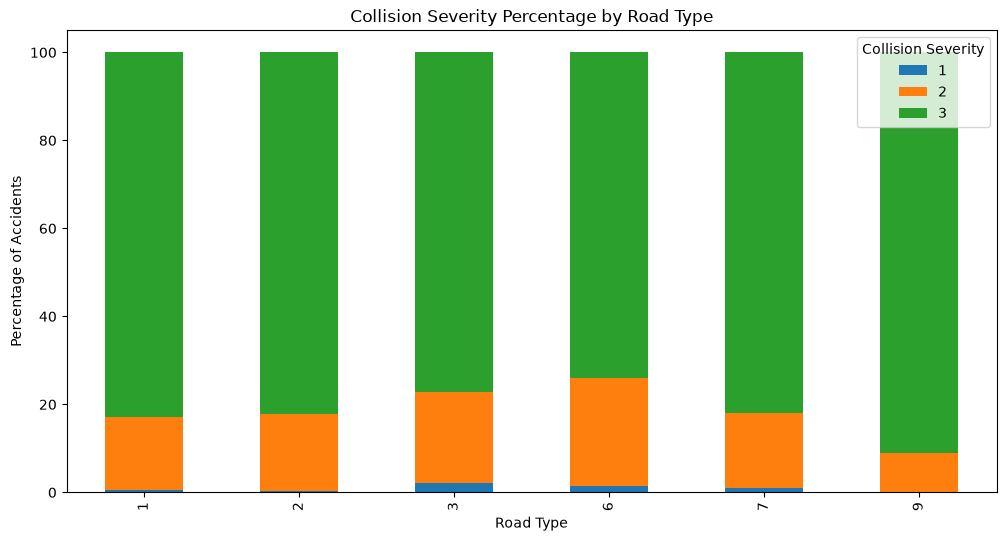

In [92]:
road_severity = pd.crosstab(
    data["road_type"],
    data["collision_severity"],
    normalize="index"
) * 100

road_severity.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("Collision Severity Percentage by Road Type")
plt.xlabel("Road Type")
plt.ylabel("Percentage of Accidents")
plt.legend(title="Collision Severity")
plt.show()

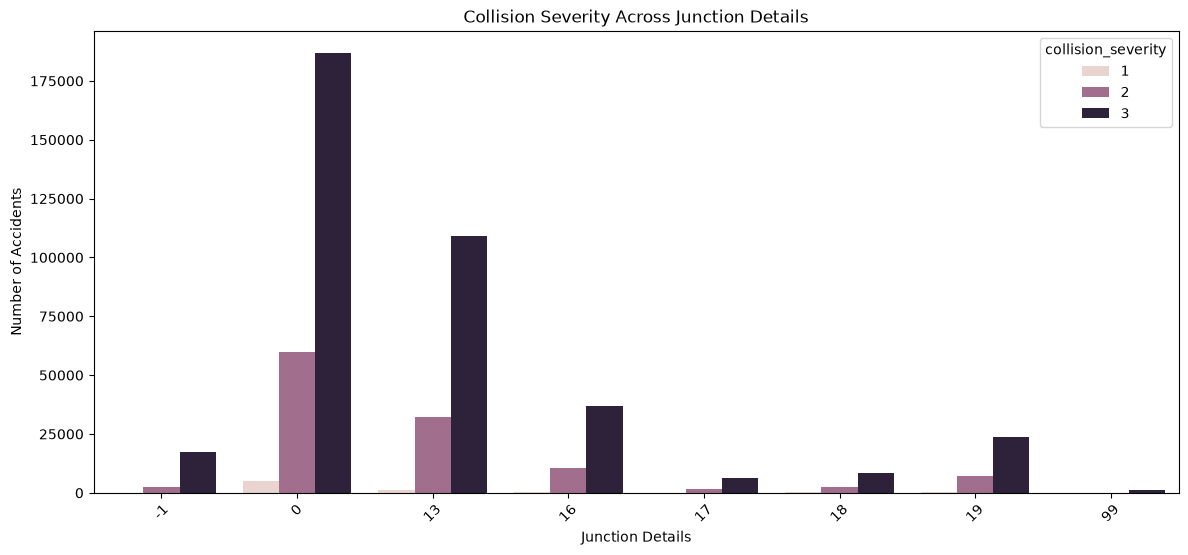

In [93]:
plt.figure(figsize=(14, 6))

sns.countplot(
    data=data,
    x="junction_detail",
    hue="collision_severity"
)

plt.title("Collision Severity Across Junction Details")
plt.xlabel("Junction Details")
plt.ylabel("Number of Accidents")
plt.xticks(rotation=45)
plt.show()

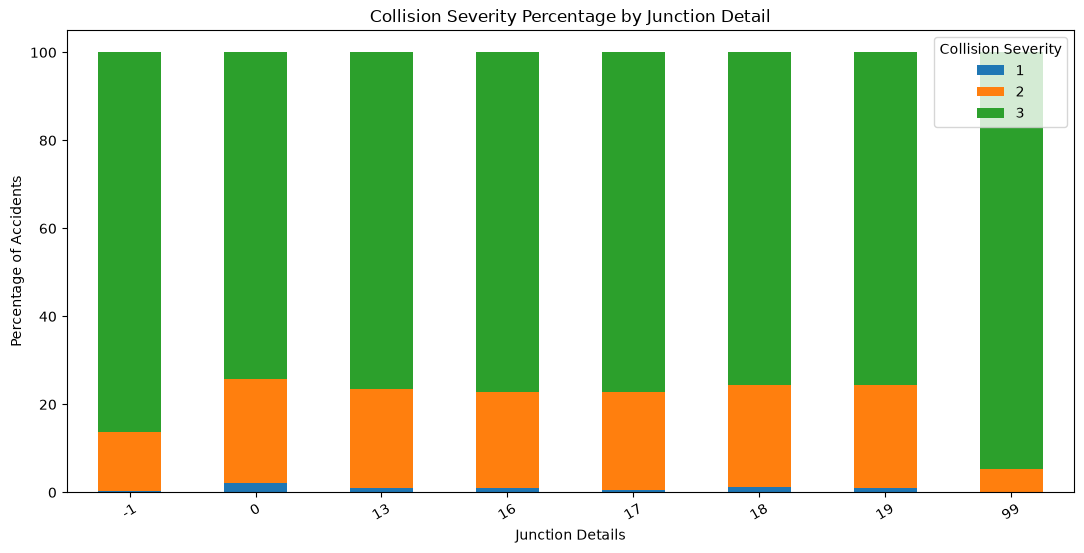

In [94]:
junction_severity = pd.crosstab(
    data["junction_detail"],
    data["collision_severity"],
    normalize="index"
) * 100

junction_severity.plot(
    kind="bar",
    stacked=True,
    figsize=(13, 6)
)

plt.title("Collision Severity Percentage by Junction Detail")
plt.xlabel("Junction Details")
plt.ylabel("Percentage of Accidents")
plt.legend(title="Collision Severity")
plt.xticks(rotation=30)
plt.show()

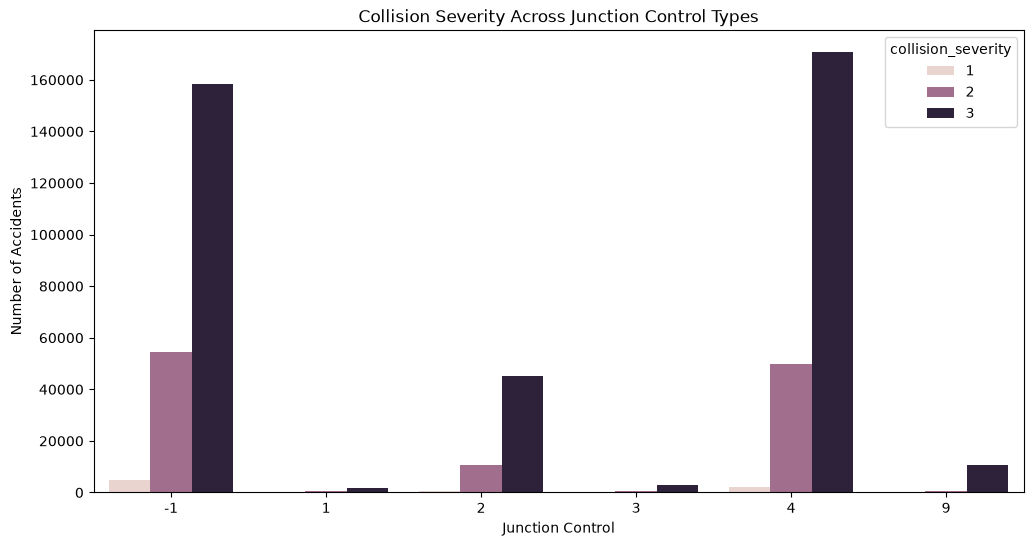

In [95]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=data,
    x="junction_control",
    hue="collision_severity"
)

plt.title("Collision Severity Across Junction Control Types")
plt.xlabel("Junction Control")
plt.ylabel("Number of Accidents")
plt.show()

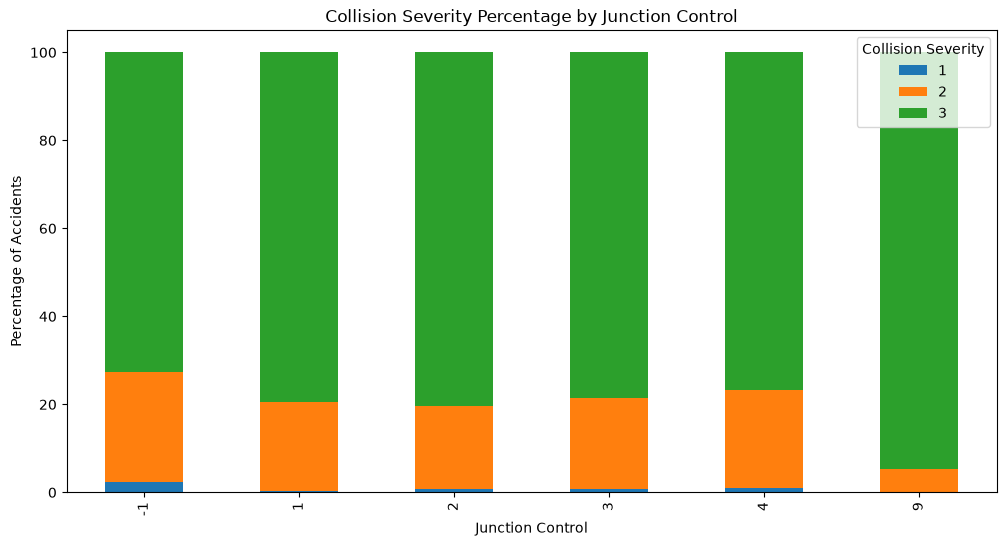

In [96]:
junction_control_severity = pd.crosstab(
    data["junction_control"],
    data["collision_severity"],
    normalize="index"
) * 100

junction_control_severity.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("Collision Severity Percentage by Junction Control")
plt.xlabel("Junction Control")
plt.ylabel("Percentage of Accidents")
plt.legend(title="Collision Severity")
plt.show()

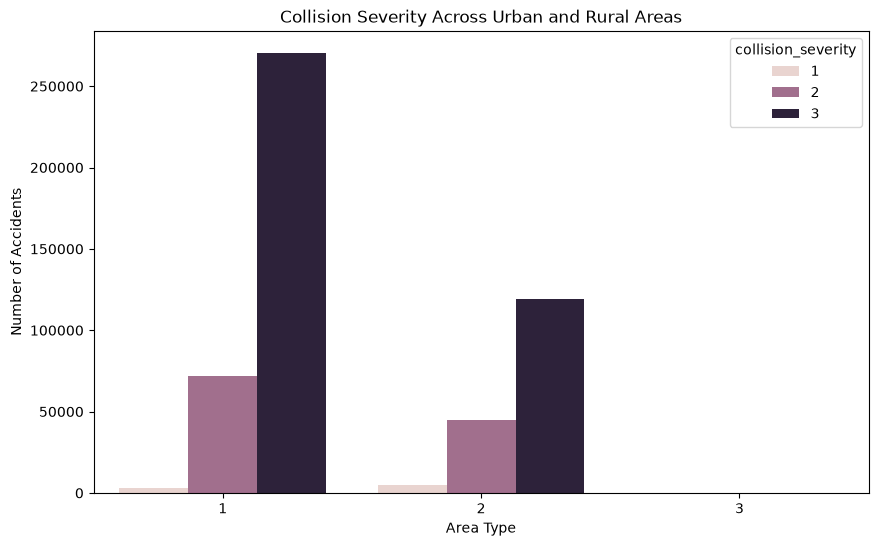

In [97]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=data,
    x="urban_or_rural_area",
    hue="collision_severity"
)

plt.title("Collision Severity Across Urban and Rural Areas")
plt.xlabel("Area Type")
plt.ylabel("Number of Accidents")
plt.show()

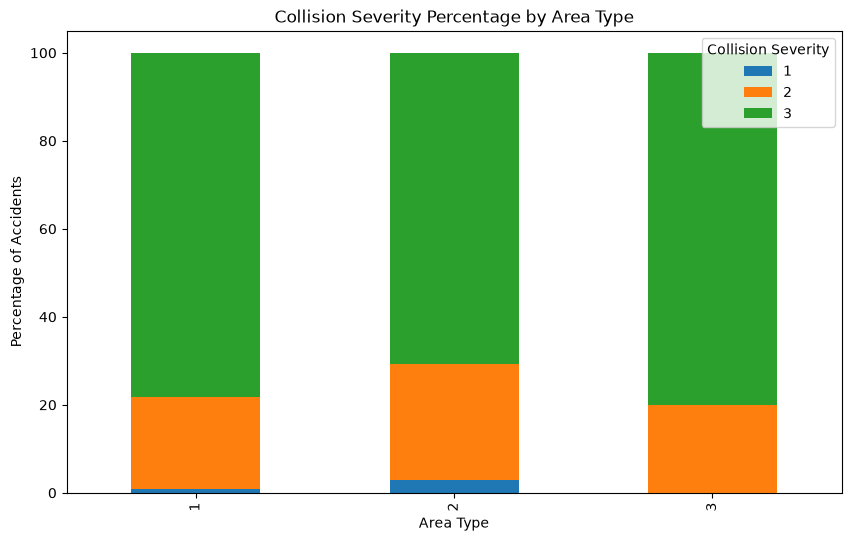

In [98]:
area_severity = pd.crosstab(
    data["urban_or_rural_area"],
    data["collision_severity"],
    normalize="index"
) * 100

area_severity.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("Collision Severity Percentage by Area Type")
plt.xlabel("Area Type")
plt.ylabel("Percentage of Accidents")
plt.legend(title="Collision Severity")
plt.show()

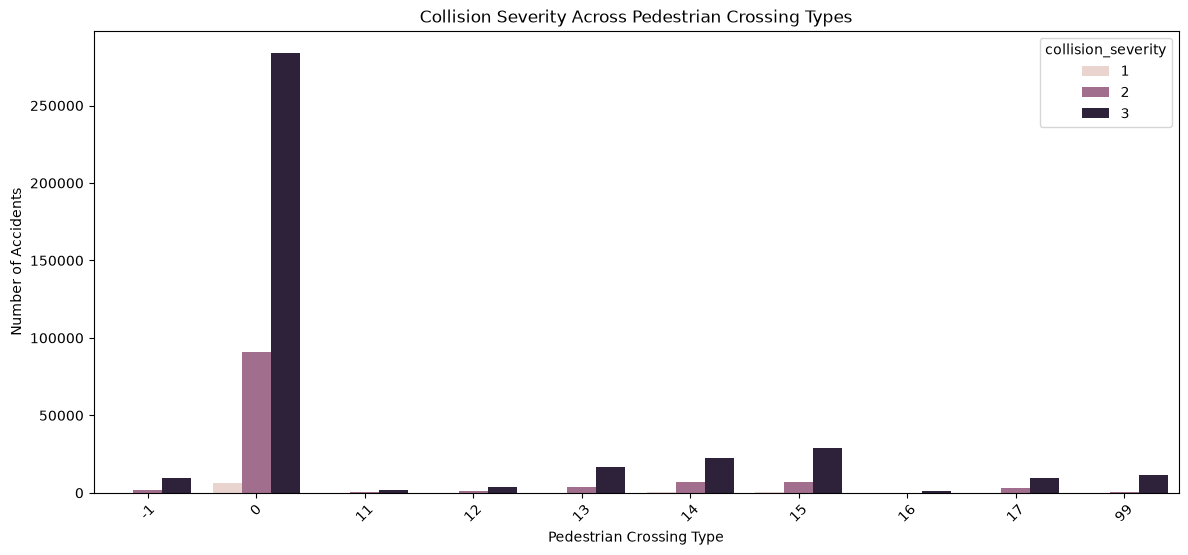

In [99]:
plt.figure(figsize=(14, 6))

sns.countplot(
    data=data,
    x="pedestrian_crossing",
    hue="collision_severity"
)

plt.title("Collision Severity Across Pedestrian Crossing Types")
plt.xlabel("Pedestrian Crossing Type")
plt.ylabel("Number of Accidents")
plt.xticks(rotation=45)
plt.show()

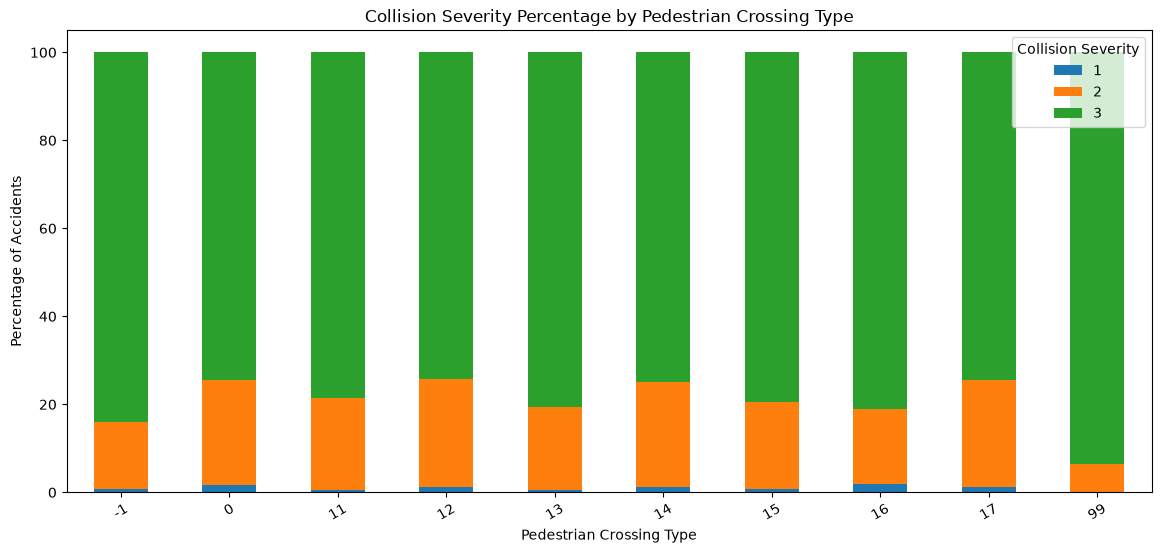

In [100]:
pedestrian_severity = pd.crosstab(
    data["pedestrian_crossing"],
    data["collision_severity"],
    normalize="index"
) * 100

pedestrian_severity.plot(
    kind="bar",
    stacked=True,
    figsize=(14, 6)
)

plt.title("Collision Severity Percentage by Pedestrian Crossing Type")
plt.xlabel("Pedestrian Crossing Type")
plt.ylabel("Percentage of Accidents")
plt.legend(title="Collision Severity")
plt.xticks(rotation=30)
plt.show()

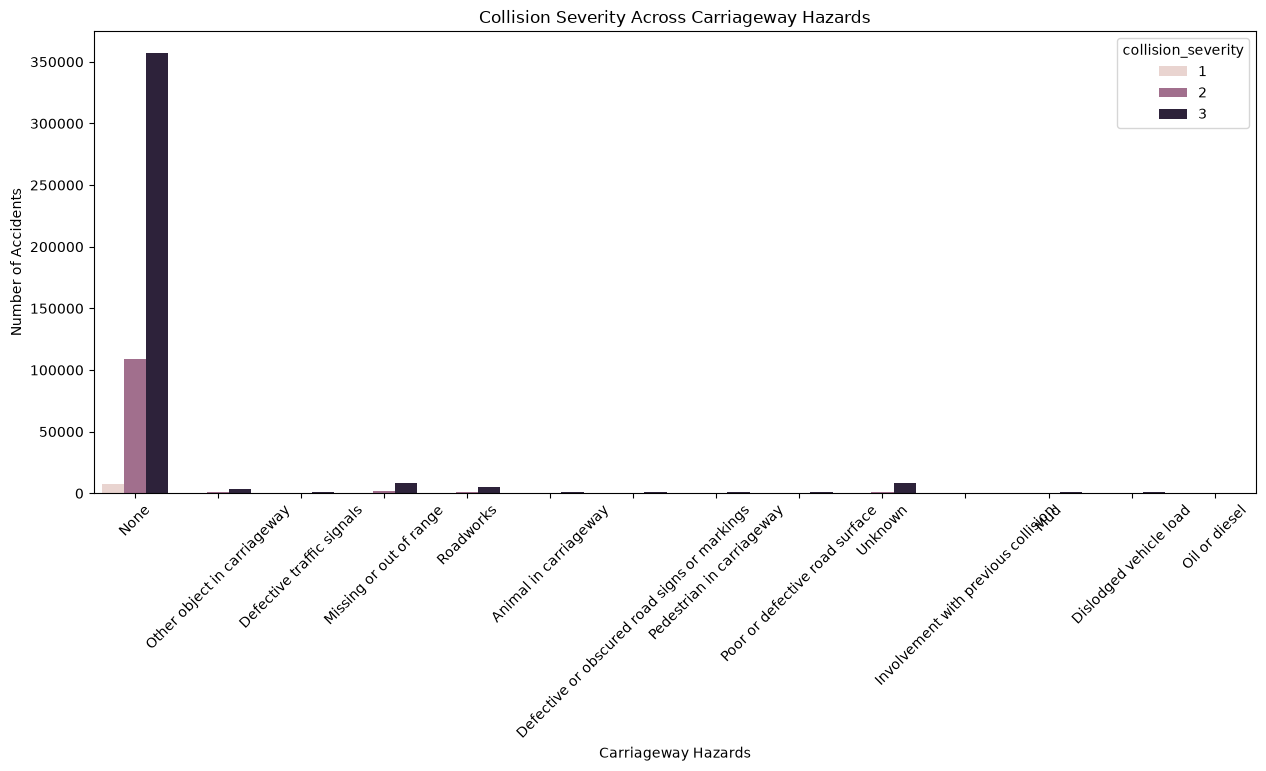

In [101]:
plt.figure(figsize=(15, 6))

sns.countplot(
    data=data,
    x="carriageway_hazards",
    hue="collision_severity"
)

plt.title("Collision Severity Across Carriageway Hazards")
plt.xlabel("Carriageway Hazards")
plt.ylabel("Number of Accidents")
plt.xticks(rotation=45)
plt.show()

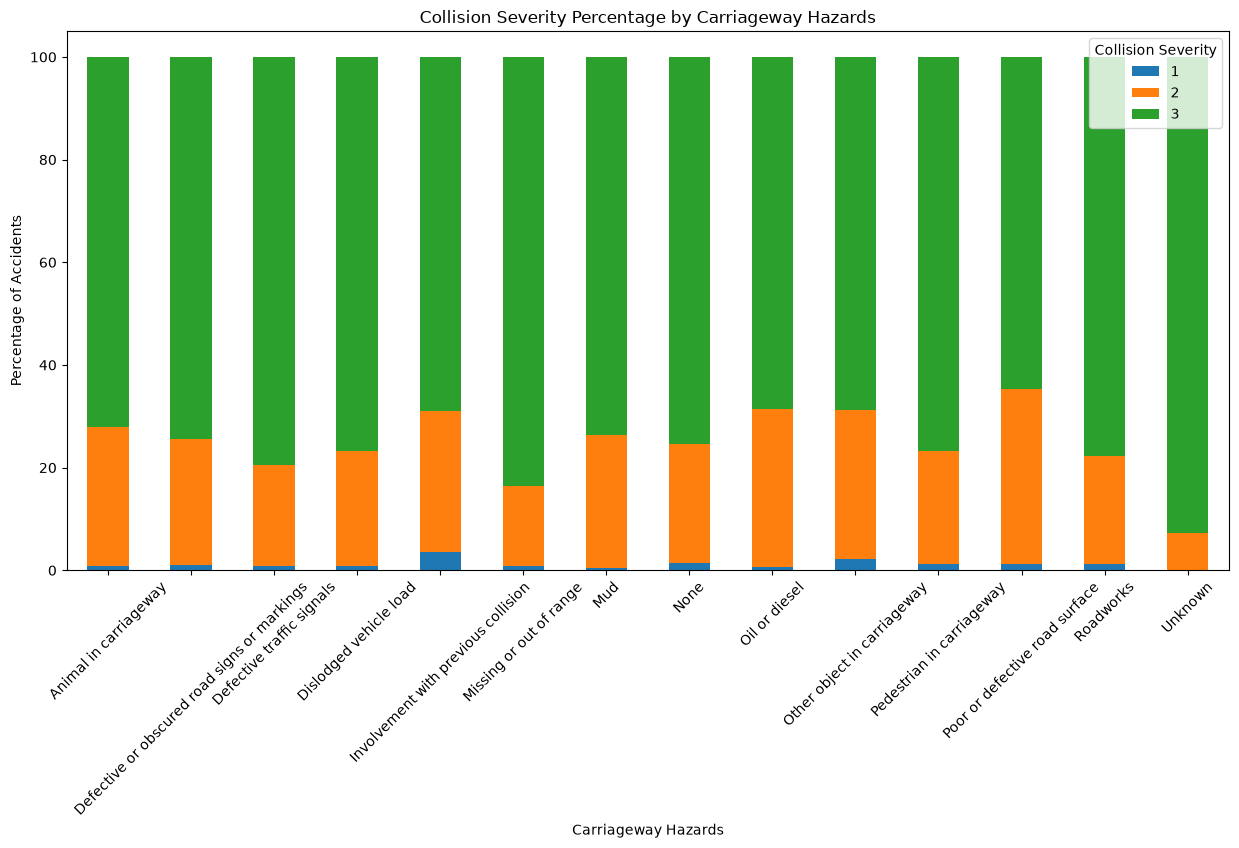

In [102]:
hazard_severity = pd.crosstab(
    data["carriageway_hazards"],
    data["collision_severity"],
    normalize="index"
) * 100

hazard_severity.plot(
    kind="bar",
    stacked=True,
    figsize=(15, 7)
)

plt.title("Collision Severity Percentage by Carriageway Hazards")
plt.xlabel("Carriageway Hazards")
plt.ylabel("Percentage of Accidents")
plt.legend(title="Collision Severity")
plt.xticks(rotation=45)
plt.show()

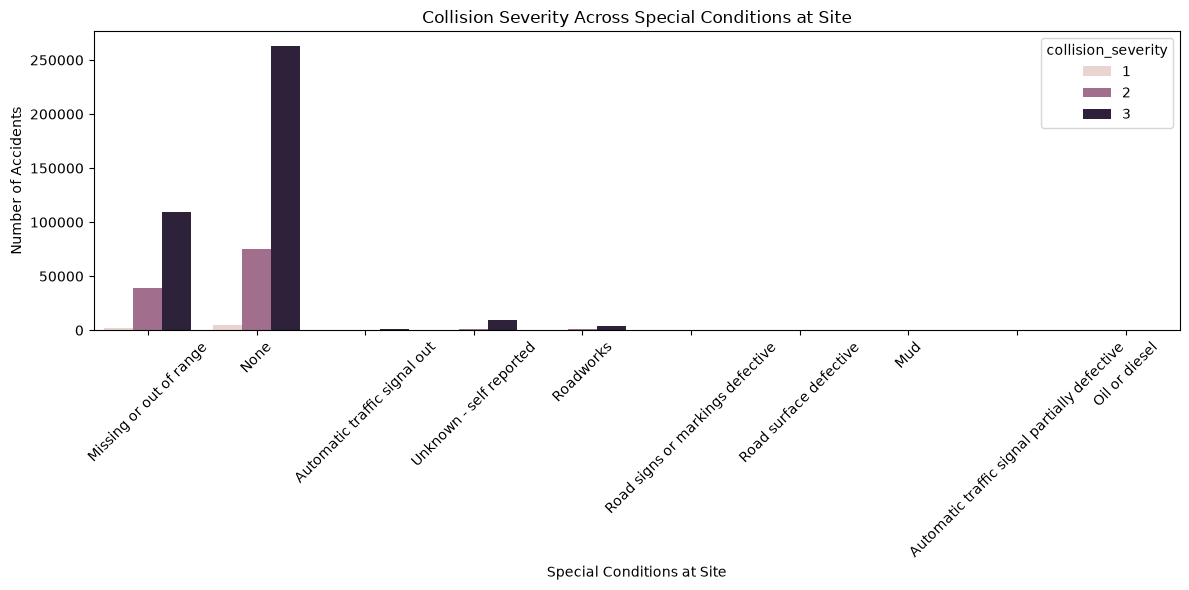

In [103]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=data,
    x="special_conditions_at_site",
    hue="collision_severity"
)

plt.title("Collision Severity Across Special Conditions at Site")
plt.xlabel("Special Conditions at Site")
plt.ylabel("Number of Accidents")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

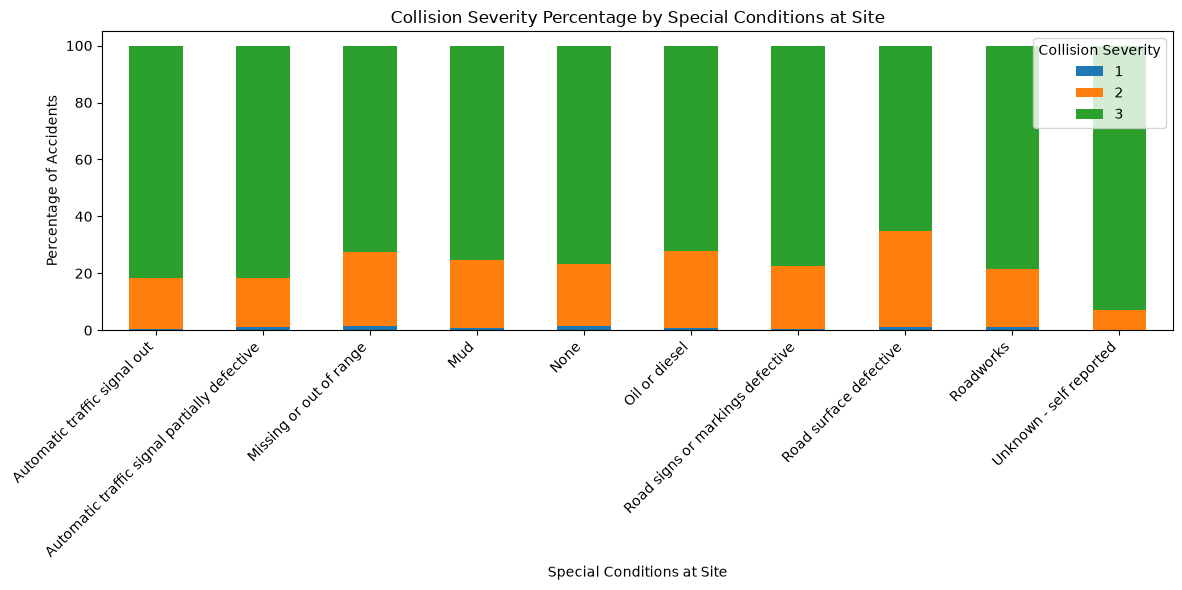

In [104]:
ct = pd.crosstab(
    data["special_conditions_at_site"],
    data["collision_severity"],
    normalize="index"
) * 100

ct.plot(kind="bar", stacked=True, figsize=(12, 6))

plt.title("Collision Severity Percentage by Special Conditions at Site")
plt.xlabel("Special Conditions at Site")
plt.ylabel("Percentage of Accidents")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Collision Severity")
plt.tight_layout()
plt.show()

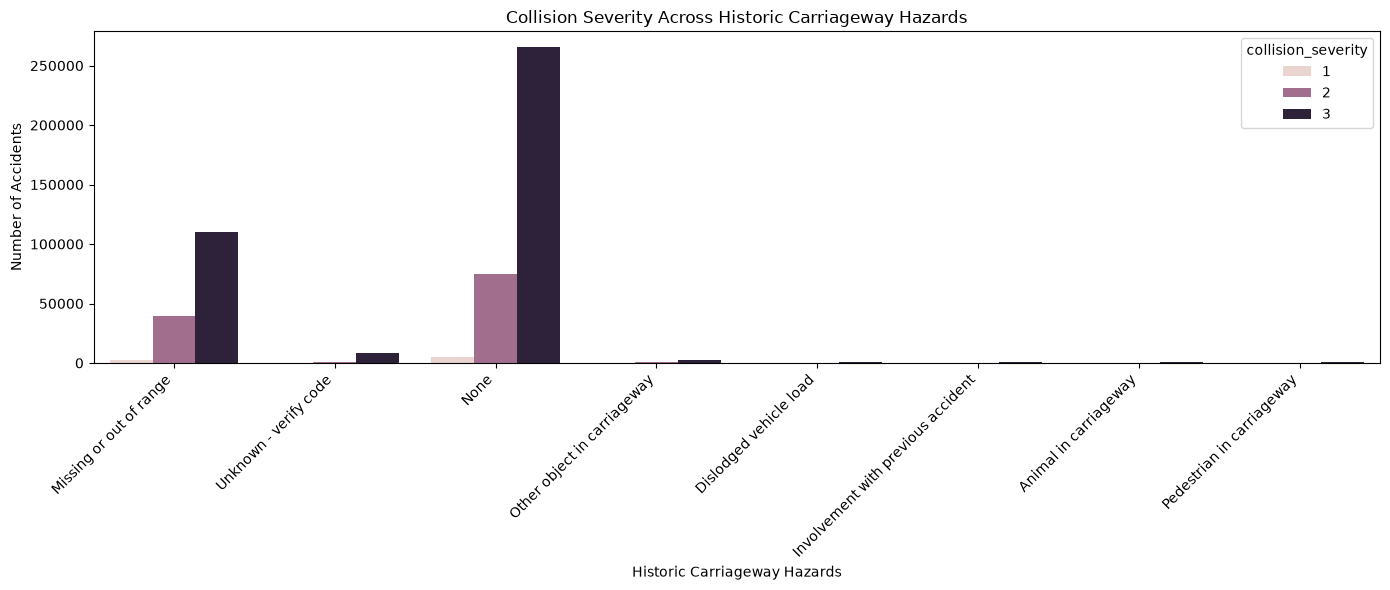

In [105]:
plt.figure(figsize=(14, 6))

sns.countplot(
    data=data,
    x="carriageway_hazards_historic",
    hue="collision_severity"
)

plt.title("Collision Severity Across Historic Carriageway Hazards")
plt.xlabel("Historic Carriageway Hazards")
plt.ylabel("Number of Accidents")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

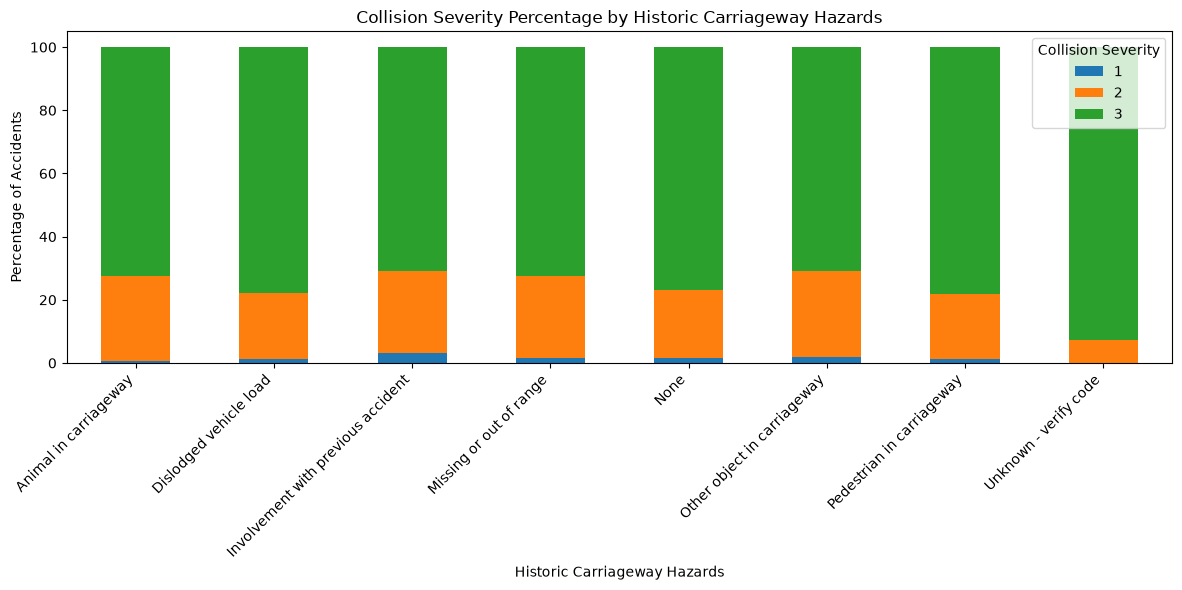

In [106]:
ct = pd.crosstab(
    data["carriageway_hazards_historic"],
    data["collision_severity"],
    normalize="index"
) * 100

ct.plot(kind="bar", stacked=True, figsize=(12, 6))

plt.title("Collision Severity Percentage by Historic Carriageway Hazards")
plt.xlabel("Historic Carriageway Hazards")
plt.ylabel("Percentage of Accidents")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Collision Severity")
plt.tight_layout()
plt.show()

In [107]:
null_counts = data.isnull().sum()
null_counts[null_counts > 0].sort_values(ascending=False)

Series([], dtype: int64)

In [108]:
data.duplicated().sum()

np.int64(0)

In [109]:
data.select_dtypes(include=["object", "str"]).nunique().sort_values()

carriageway_hazards_historic            8
special_conditions_at_site             10
carriageway_hazards                    14
local_authority_highway_current       207
local_authority_highway               211
local_authority_ons_district          370
time                                 1440
date                                 1826
lsoa_of_accident_location           35630
collision_ref_no                   510784
collision_index                    513748
dtype: int64

In [110]:
data[["collision_index", "collision_ref_no"]].head()

,collision_index,collision_ref_no
0,202417H105824,17H105824
1,202517M115025,17M115025
2,202517L306225,17L306225
3,202417S104724,17S104724
4,202517S106525,17S106525


In [111]:
X = data.drop(columns=[
    "collision_index",
    "collision_ref_no",
    "collision_severity"
])

y = data["collision_severity"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (513748, 41)
Target shape: (513748,)


In [112]:
X.dtypes.value_counts()

int64      26
str         9
float64     6
Name: count, dtype: int64

In [113]:
X.select_dtypes(include=["str"]).columns

Index(['date', 'time', 'local_authority_ons_district',
       'local_authority_highway', 'local_authority_highway_current',
       'special_conditions_at_site', 'carriageway_hazards_historic',
       'carriageway_hazards', 'lsoa_of_accident_location'],
      dtype='str')

In [114]:
X[["date", "time"]].head(10)

,date,time
0,03/10/2024,16:06
1,29/11/2025,16:34
2,01/06/2025,22:07
3,20/04/2024,14:40
4,16/05/2025,07:25
5,22/06/2025,13:30
6,13/07/2025,15:10
7,13/05/2024,12:10
8,20/06/2024,16:30
9,30/04/2025,16:31


In [115]:
X["date"] = pd.to_datetime(
    X["date"],
    format="%d/%m/%Y"
)

In [116]:
X["date"].dtype

dtype('<M8[us]')

In [117]:
X["year"] = X["date"].dt.year
X["month"] = X["date"].dt.month
X["day_of_week"] = X["date"].dt.dayofweek

In [118]:
X[["date", "year", "month", "day_of_week"]].head()

,date,year,month,day_of_week
0,2024-10-03,2024,10,3
1,2025-11-29,2025,11,5
2,2025-06-01,2025,6,6
3,2024-04-20,2024,4,5
4,2025-05-16,2025,5,4


In [119]:
X.drop(columns=["date"], inplace=True)

In [120]:
X["time"] = pd.to_datetime(
    X["time"],
    format="%H:%M"
)

In [121]:
X["hour"] = X["time"].dt.hour

In [122]:
X[["time", "hour"]].head(10)

,time,hour
0,1900-01-01 16:06:00,16
1,1900-01-01 16:34:00,16
2,1900-01-01 22:07:00,22
3,1900-01-01 14:40:00,14
4,1900-01-01 07:25:00,7
5,1900-01-01 13:30:00,13
6,1900-01-01 15:10:00,15
7,1900-01-01 12:10:00,12
8,1900-01-01 16:30:00,16
9,1900-01-01 16:31:00,16


In [123]:
X.drop(columns=["time"], inplace=True)

In [124]:
local_cols = [
    "local_authority_ons_district",
    "local_authority_highway",
    "local_authority_highway_current"
]

for col in local_cols:
    print(f"\n{col}")
    print("Unique values:", X[col].nunique())
    print(X[col].value_counts().head(5))


local_authority_ons_district
Unique values: 370
local_authority_ons_district
E08000025    11322
E08000035     7298
E09000033     5887
E09000022     5221
E08000032     5163
Name: count, dtype: int64

local_authority_highway
Unique values: 211
local_authority_highway
E10000016    15934
E10000030    12953
E10000012    11594
E08000025    11322
E10000014    11241
Name: count, dtype: int64

local_authority_highway_current
Unique values: 207
local_authority_highway_current
E10000016    15934
E10000030    12955
E10000012    11593
E08000025    11315
E10000014    11240
Name: count, dtype: int64


In [125]:
(X["local_authority_highway"] ==
 X["local_authority_highway_current"]).value_counts()

True     506186
False      7562
Name: count, dtype: int64

In [126]:
X.loc[
    X["local_authority_highway"] != X["local_authority_highway_current"],
    ["local_authority_highway", "local_authority_highway_current"]
].head(10)

,local_authority_highway,local_authority_highway_current
158,E08000016,E08000038
159,E08000016,E08000038
160,E08000016,E08000038
161,E08000016,E08000038
162,E08000016,E08000038
170,E08000019,E08000039
171,E08000019,E08000039
172,E08000019,E08000039
173,E08000019,E08000039
174,E08000019,E08000039


In [127]:
X.drop(columns=["local_authority_highway"], inplace=True)

In [128]:
geo_cols = [
    "local_authority_ons_district",
    "local_authority_highway_current",
    "lsoa_of_accident_location"
]

for col in geo_cols:
    print(f"\n{col}")
    print("Unique:", X[col].nunique())
    print("Missing:", X[col].isnull().sum())


local_authority_ons_district
Unique: 370
Missing: 0

local_authority_highway_current
Unique: 207
Missing: 0

lsoa_of_accident_location
Unique: 35630
Missing: 0


In [129]:
cat_cols = [
    "special_conditions_at_site",
    "carriageway_hazards",
    "carriageway_hazards_historic"
]

for col in cat_cols:
    print(f"\n{col}")
    print(X[col].value_counts().head(15))


special_conditions_at_site
special_conditions_at_site
None                                            343468
Missing or out of range                         151370
Unknown - self reported                          10558
Roadworks                                         4466
Automatic traffic signal out                      1081
Road surface defective                             841
Mud                                                782
Road signs or markings defective                   580
Oil or diesel                                      418
Automatic traffic signal partially defective       184
Name: count, dtype: int64

carriageway_hazards
carriageway_hazards
None                                            473274
Missing or out of range                           9891
Unknown                                           9172
Roadworks                                         6098
Other object in carriageway                       4790
Defective traffic signals                         165

In [130]:
for col in cat_cols:
    print(f"\n{col}")
    print(pd.crosstab(data["collision_year"], data[col]))


special_conditions_at_site
special_conditions_at_site  Automatic traffic signal out  \
collision_year                                             
2021                                                 319   
2022                                                 297   
2023                                                 297   
2024                                                 134   
2025                                                  34   

special_conditions_at_site  Automatic traffic signal partially defective  \
collision_year                                                             
2021                                                                  51   
2022                                                                  54   
2023                                                                  45   
2024                                                                  26   
2025                                                                   8   

special_conditions

In [131]:
check_cols = [
    "special_conditions_at_site",
    "carriageway_hazards",
    "carriageway_hazards_historic"
]

for col in check_cols:
    print(f"\n{col}")

    print(
        pd.crosstab(
            data["collision_year"],
            data[col],
            normalize="index"
        ).mul(100).round(2)
    )


special_conditions_at_site
special_conditions_at_site  Automatic traffic signal out  \
collision_year                                             
2021                                                0.32   
2022                                                0.28   
2023                                                0.28   
2024                                                0.13   
2025                                                0.03   

special_conditions_at_site  Automatic traffic signal partially defective  \
collision_year                                                             
2021                                                                0.05   
2022                                                                0.05   
2023                                                                0.04   
2024                                                                0.03   
2025                                                                0.01   

special_conditions

In [132]:
pd.crosstab(
    data["special_conditions_at_site"],
    data["carriageway_hazards_historic"]
)

carriageway_hazards_historic,Animal in carriageway,Dislodged vehicle load,Involvement with previous accident,Missing or out of range,None,Other object in carriageway,Pedestrian in carriageway,Unknown - verify code
special_conditions_at_site,,,,,,,,
Automatic traffic signal out,3,31,9,3,968,25,6,36
Automatic traffic signal partially defective,0,0,2,0,163,5,7,7
Missing or out of range,2,0,0,151274,91,2,1,0
Mud,8,6,0,0,724,22,2,20
None,1093,825,604,85,335708,3327,794,1032
Oil or diesel,1,7,5,0,375,25,0,5
Road signs or markings defective,1,6,7,0,512,24,4,26
Road surface defective,4,8,5,0,708,81,2,33
Roadworks,0,12,13,5,3978,355,26,77


In [133]:
cols = [
    "special_conditions_at_site",
    "carriageway_hazards_historic",
    "carriageway_hazards"
]

for col in cols:
    print(f"\n{col}")
    print(
        (data[col] == "Missing or out of range")
        .groupby(data["collision_year"])
        .mean()
        .mul(100)
        .round(2)
    )


special_conditions_at_site
collision_year
2021     0.35
2022     0.70
2023     2.99
2024    58.75
2025    86.54
Name: special_conditions_at_site, dtype: float64

carriageway_hazards_historic
collision_year
2021     0.34
2022     0.70
2023     3.00
2024    58.76
2025    86.53
Name: carriageway_hazards_historic, dtype: float64

carriageway_hazards
collision_year
2021    0.32
2022    0.67
2023    2.96
2024    0.42
2025    5.27
Name: carriageway_hazards, dtype: float64


In [134]:
pd.crosstab(
    data["collision_year"],
    data["carriageway_hazards"].eq("Missing or out of range"),
    normalize="index"
).mul(100).round(2)

carriageway_hazards,False,True
collision_year,,
2021,99.68,0.32
2022,99.33,0.67
2023,97.04,2.96
2024,99.58,0.42
2025,94.73,5.27


In [135]:
pd.crosstab(
    data["special_conditions_at_site"],
    data["carriageway_hazards"],
    normalize="index"
).round(3)

carriageway_hazards,Animal in carriageway,Defective or obscured road signs or markings,Defective traffic signals,Dislodged vehicle load,Involvement with previous collision,Missing or out of range,Mud,None,Oil or diesel,Other object in carriageway,Pedestrian in carriageway,Poor or defective road surface,Roadworks,Unknown
special_conditions_at_site,,,,,,,,,,,,,,
Automatic traffic signal out,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Automatic traffic signal partially defective,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Missing or out of range,0.002,0.002,0.003,0.001,0.002,0.065,0.003,0.886,0.001,0.009,0.002,0.005,0.011,0.007
Mud,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
None,0.003,0.000,0.000,0.002,0.002,0.000,0.000,0.981,0.000,0.010,0.002,0.000,0.000,0.000
Oil or diesel,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000
Road signs or markings defective,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Road surface defective,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000
Roadworks,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000


In [136]:
for year in sorted(data["collision_year"].unique()):
    subset = data[data["collision_year"] == year]

    print(f"\nYear: {year}")
    print(
        pd.crosstab(
            subset["special_conditions_at_site"],
            subset["carriageway_hazards"],
            normalize="index"
        ).round(2)
    )


Year: 2021
carriageway_hazards                           Animal in carriageway  \
special_conditions_at_site                                            
Automatic traffic signal out                                    0.0   
Automatic traffic signal partially defective                    0.0   
Missing or out of range                                         0.0   
Mud                                                             0.0   
None                                                            0.0   
Oil or diesel                                                   0.0   
Road signs or markings defective                                0.0   
Road surface defective                                          0.0   
Roadworks                                                       0.0   
Unknown - self reported                                         0.0   

carriageway_hazards                           Defective or obscured road signs or markings  \
special_conditions_at_site               

In [137]:
cols = [
    "special_conditions_at_site",
    "carriageway_hazards_historic",
    "carriageway_hazards"
]

for col in cols:
    print(f"\n{col}")
    print("Missing:", data[col].isna().sum())
    print("Missing/out-of-range:",
          (data[col] == "Missing or out of range").sum())


special_conditions_at_site
Missing: 0
Missing/out-of-range: 151370

carriageway_hazards_historic
Missing: 0
Missing/out-of-range: 151367

carriageway_hazards
Missing: 0
Missing/out-of-range: 9891


In [138]:
for col in cols:
    print(f"\n{col}")
    print(data.groupby("collision_year")[col]
          .apply(lambda s: (s == "Missing or out of range").sum()))


special_conditions_at_site
collision_year
2021      351
2022      746
2023     3116
2024    59299
2025    87858
Name: special_conditions_at_site, dtype: int64

carriageway_hazards_historic
collision_year
2021      342
2022      746
2023     3127
2024    59300
2025    87852
Name: carriageway_hazards_historic, dtype: int64

carriageway_hazards
collision_year
2021     325
2022     713
2023    3086
2024     421
2025    5346
Name: carriageway_hazards, dtype: int64


In [139]:
data["collision_severity"].value_counts(dropna=False)

collision_severity
3    389399
2    116797
1      7552
Name: count, dtype: int64

In [140]:
data["collision_severity"].value_counts(normalize=True).mul(100).round(2)

collision_severity
3    75.80
2    22.73
1     1.47
Name: proportion, dtype: float64

In [141]:
num_cols = X.select_dtypes(include="number").columns.tolist()
print(num_cols)

['collision_year', 'location_easting_osgr', 'location_northing_osgr', 'longitude', 'latitude', 'police_force', 'number_of_vehicles', 'number_of_casualties', 'day_of_week', 'local_authority_district', 'first_road_class', 'first_road_number', 'road_type', 'speed_limit', 'junction_detail_historic', 'junction_detail', 'junction_control', 'second_road_class', 'second_road_number', 'pedestrian_crossing_human_control_historic', 'pedestrian_crossing_physical_facilities_historic', 'pedestrian_crossing', 'light_conditions', 'weather_conditions', 'road_surface_conditions', 'urban_or_rural_area', 'did_police_officer_attend_scene_of_accident', 'trunk_road_flag', 'enhanced_severity_collision', 'collision_injury_based', 'collision_adjusted_severity_serious', 'collision_adjusted_severity_slight', 'year', 'month', 'hour']


In [142]:
X[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
collision_year,513748.0,2022.991924,1.407144,2021.000000,2022.000000,2023.000000,2024.000000,2.025000e+03
location_easting_osgr,513748.0,454945.487375,92658.538917,67564.000000,392630.000000,460443.500000,529549.250000,6.553450e+05
location_northing_osgr,513748.0,275427.620133,145647.350208,10211.000000,175147.000000,217372.500000,382395.000000,1.179892e+06
longitude,513748.0,-1.211037,1.355154,-7.486852,-2.111008,-1.106897,-0.133341,1.759829e+00
latitude,513748.0,52.366318,1.312262,49.912210,51.462346,51.843188,53.334331,6.050001e+01
police_force,513748.0,27.604902,24.207957,1.000000,5.000000,22.000000,45.000000,9.900000e+01
number_of_vehicles,513748.0,1.824171,0.687805,1.000000,1.000000,2.000000,2.000000,2.600000e+01
number_of_casualties,513748.0,1.270590,0.726377,1.000000,1.000000,1.000000,1.000000,1.420000e+02
day_of_week,513748.0,2.924989,1.921415,0.000000,1.000000,3.000000,4.000000,6.000000e+00
local_authority_district,513748.0,-0.872449,6.926291,-1.000000,-1.000000,-1.000000,-1.000000,4.800000e+02


In [143]:
severity_cols = [
    "collision_injury_based",
    "collision_adjusted_severity_serious",
    "collision_adjusted_severity_slight",
    "enhanced_severity_collision"
]

data[["collision_severity"] + severity_cols].head(10)

,collision_severity,collision_injury_based,collision_adjusted_severity_serious,collision_adjusted_severity_slight,enhanced_severity_collision
0,2,1,1.0,0.0,7
1,2,1,1.0,0.0,6
2,3,1,0.0,1.0,3
3,3,1,0.0,1.0,3
4,2,1,1.0,0.0,7
5,3,1,0.0,1.0,3
6,3,1,0.0,1.0,3
7,3,1,0.0,1.0,3
8,2,1,1.0,0.0,7
9,3,1,0.0,1.0,3


In [144]:
X = X.drop(columns=severity_cols)
print(X.shape)

(513748, 37)


In [145]:
print("Severity columns still in X:")
print([col for col in severity_cols if col in X.columns])

print("\nID columns still in X:")
print([col for col in ["collision_index", "collision_ref_no"] if col in X.columns])

Severity columns still in X:
[]

ID columns still in X:
[]


In [146]:
(X["year"] == data["collision_year"]).value_counts()

True    513748
Name: count, dtype: int64

In [147]:
X = X.drop(columns=["collision_year"])

In [148]:
X.columns

Index(['location_easting_osgr', 'location_northing_osgr', 'longitude',
       'latitude', 'police_force', 'number_of_vehicles',
       'number_of_casualties', 'day_of_week', 'local_authority_district',
       'local_authority_ons_district', 'local_authority_highway_current',
       'first_road_class', 'first_road_number', 'road_type', 'speed_limit',
       'junction_detail_historic', 'junction_detail', 'junction_control',
       'second_road_class', 'second_road_number',
       'pedestrian_crossing_human_control_historic',
       'pedestrian_crossing_physical_facilities_historic',
       'pedestrian_crossing', 'light_conditions', 'weather_conditions',
       'road_surface_conditions', 'special_conditions_at_site',
       'carriageway_hazards_historic', 'carriageway_hazards',
       'urban_or_rural_area', 'did_police_officer_attend_scene_of_accident',
       'trunk_road_flag', 'lsoa_of_accident_location', 'year', 'month',
       'hour'],
      dtype='str')

In [149]:
X.shape

(513748, 36)

In [150]:
X.duplicated().sum()

np.int64(2)

In [151]:
cols = X.columns.tolist()
duplicate_cols = []

for i in range(len(cols)):
    for j in range(i + 1, len(cols)):
        if X[cols[i]].equals(X[cols[j]]):
            duplicate_cols.append(cols[j])

print("Duplicate columns:", duplicate_cols)

Duplicate columns: []


In [152]:
print("Categorical columns:")
print(X.select_dtypes(include=["object", "category"]).columns.tolist())

print("\nNumerical columns:")
print(X.select_dtypes(include="number").columns.tolist())

Categorical columns:


C:\Users\BANAPURAM VINAY TEJA\AppData\Local\Temp\ipykernel_28072\2499442632.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(X.select_dtypes(include=["object", "category"]).columns.tolist())


['local_authority_ons_district', 'local_authority_highway_current', 'special_conditions_at_site', 'carriageway_hazards_historic', 'carriageway_hazards', 'lsoa_of_accident_location']

Numerical columns:
['location_easting_osgr', 'location_northing_osgr', 'longitude', 'latitude', 'police_force', 'number_of_vehicles', 'number_of_casualties', 'day_of_week', 'local_authority_district', 'first_road_class', 'first_road_number', 'road_type', 'speed_limit', 'junction_detail_historic', 'junction_detail', 'junction_control', 'second_road_class', 'second_road_number', 'pedestrian_crossing_human_control_historic', 'pedestrian_crossing_physical_facilities_historic', 'pedestrian_crossing', 'light_conditions', 'weather_conditions', 'road_surface_conditions', 'urban_or_rural_area', 'did_police_officer_attend_scene_of_accident', 'trunk_road_flag', 'year', 'month', 'hour']


In [153]:
cat_num_cols = [
    "police_force",
    "first_road_class",
    "road_type",
    "junction_detail_historic",
    "junction_detail",
    "junction_control",
    "second_road_class",
    "pedestrian_crossing_human_control_historic",
    "pedestrian_crossing_physical_facilities_historic",
    "pedestrian_crossing",
    "light_conditions",
    "weather_conditions",
    "road_surface_conditions",
    "urban_or_rural_area",
    "did_police_officer_attend_scene_of_accident",
    "trunk_road_flag"
]

print(X[cat_num_cols].nunique().sort_values())

trunk_road_flag                                      3
urban_or_rural_area                                  3
did_police_officer_attend_scene_of_accident          3
pedestrian_crossing_human_control_historic           5
light_conditions                                     6
road_type                                            6
junction_control                                     6
first_road_class                                     7
road_surface_conditions                              7
pedestrian_crossing_physical_facilities_historic     8
junction_detail                                      8
second_road_class                                    9
weather_conditions                                  10
pedestrian_crossing                                 10
junction_detail_historic                            11
police_force                                        44
dtype: int64


In [154]:
X.head(20)

,location_easting_osgr,location_northing_osgr,longitude,latitude,police_force,number_of_vehicles,number_of_casualties,day_of_week,local_authority_district,local_authority_ons_district,...,special_conditions_at_site,carriageway_hazards_historic,carriageway_hazards,urban_or_rural_area,did_police_officer_attend_scene_of_accident,trunk_road_flag,lsoa_of_accident_location,year,month,hour
0,448628.0,533968.0,-1.24700,54.69840,17,2,1,3,-1,E06000001,...,Missing or out of range,Missing or out of range,None,1,1,2,E01012005,2024,10,16
1,452379.0,519038.0,-1.19147,54.56387,17,2,1,5,-1,E06000002,...,Missing or out of range,Missing or out of range,None,1,1,2,E01012090,2025,11,16
2,459273.0,523811.0,-1.08390,54.60600,17,2,3,6,-1,E06000003,...,Missing or out of range,Missing or out of range,None,1,1,2,E01032560,2025,6,22
3,440460.0,517548.0,-1.37599,54.55157,17,2,2,5,-1,E06000004,...,Missing or out of range,Missing or out of range,None,2,1,1,E01012269,2024,4,14
4,444331.0,518776.0,-1.31596,54.56228,17,2,1,4,-1,E06000004,...,Missing or out of range,Missing or out of range,None,1,1,2,E01035199,2025,5,7
5,445551.0,522882.0,-1.29646,54.59907,17,2,1,6,-1,E06000004,...,Missing or out of range,Missing or out of range,None,1,3,2,E01012280,2025,6,13
6,445075.0,522729.0,-1.30385,54.59774,17,2,1,6,-1,E06000004,...,Missing or out of range,Missing or out of range,None,2,2,1,E01012210,2025,7,15
7,429273.0,514457.0,-1.54924,54.52456,11,2,3,0,-1,E06000005,...,Missing or out of range,Missing or out of range,None,1,1,2,E01035187,2024,5,12
8,427874.0,512656.0,-1.57102,54.50845,11,3,1,3,-1,E06000005,...,Missing or out of range,Missing or out of range,None,2,3,2,E01012361,2024,6,16
9,355532.0,390976.0,-2.67047,53.41371,7,4,1,2,-1,E06000007,...,Missing or out of range,Missing or out of range,None,2,1,1,E01012469,2025,4,16


In [155]:
num_cols = X.select_dtypes(include="number").columns.tolist()

continuous_candidates = [
    col for col in num_cols
    if col not in cat_num_cols
]
print(continuous_candidates)

['location_easting_osgr', 'location_northing_osgr', 'longitude', 'latitude', 'number_of_vehicles', 'number_of_casualties', 'day_of_week', 'local_authority_district', 'first_road_number', 'speed_limit', 'second_road_number', 'year', 'month', 'hour']


In [156]:
X[continuous_candidates].nunique().sort_values()

year                             5
day_of_week                      7
speed_limit                      7
month                           12
local_authority_district        15
number_of_vehicles              19
hour                            24
number_of_casualties            26
second_road_number            3356
first_road_number             3616
location_easting_osgr       245276
location_northing_osgr      263601
latitude                    412450
longitude                   437862
dtype: int64

In [157]:
road_cols = ["first_road_number", "second_road_number"]

X[road_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
first_road_number,513748.0,789.263571,1583.161488,-1.0,0.0,31.0,538.0,9999.0
second_road_number,513748.0,233.432872,955.950728,-1.0,-1.0,0.0,0.0,9999.0


In [158]:
X = X.drop(columns=road_cols)
print(X.shape)

(513748, 34)


In [159]:
cat_num_cols = [
    col for col in cat_num_cols
    if col in X.columns
]

print(cat_num_cols)

['police_force', 'first_road_class', 'road_type', 'junction_detail_historic', 'junction_detail', 'junction_control', 'second_road_class', 'pedestrian_crossing_human_control_historic', 'pedestrian_crossing_physical_facilities_historic', 'pedestrian_crossing', 'light_conditions', 'weather_conditions', 'road_surface_conditions', 'urban_or_rural_area', 'did_police_officer_attend_scene_of_accident', 'trunk_road_flag']


In [160]:
cat_cols = cat_num_cols + [
    col for col in X.select_dtypes(include=["object", "category"]).columns
    if col not in cat_num_cols
]
print("Total categorical features:", len(cat_cols))
print(cat_cols)

Total categorical features: 22
['police_force', 'first_road_class', 'road_type', 'junction_detail_historic', 'junction_detail', 'junction_control', 'second_road_class', 'pedestrian_crossing_human_control_historic', 'pedestrian_crossing_physical_facilities_historic', 'pedestrian_crossing', 'light_conditions', 'weather_conditions', 'road_surface_conditions', 'urban_or_rural_area', 'did_police_officer_attend_scene_of_accident', 'trunk_road_flag', 'local_authority_ons_district', 'local_authority_highway_current', 'special_conditions_at_site', 'carriageway_hazards_historic', 'carriageway_hazards', 'lsoa_of_accident_location']


C:\Users\BANAPURAM VINAY TEJA\AppData\Local\Temp\ipykernel_28072\434540012.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  col for col in X.select_dtypes(include=["object", "category"]).columns


In [161]:
X[cat_cols].nunique().sort_values(ascending=False)

lsoa_of_accident_location                           35630
local_authority_ons_district                          370
local_authority_highway_current                       207
police_force                                           44
carriageway_hazards                                    14
junction_detail_historic                               11
pedestrian_crossing                                    10
weather_conditions                                     10
special_conditions_at_site                             10
second_road_class                                       9
pedestrian_crossing_physical_facilities_historic        8
carriageway_hazards_historic                            8
junction_detail                                         8
first_road_class                                        7
road_surface_conditions                                 7
road_type                                               6
junction_control                                        6
light_conditio

In [162]:
num_cols = [
    col for col in X.select_dtypes(include="number").columns
    if col not in cat_cols
]

print("Numerical features:", len(num_cols))
print(num_cols)

Numerical features: 12
['location_easting_osgr', 'location_northing_osgr', 'longitude', 'latitude', 'number_of_vehicles', 'number_of_casualties', 'day_of_week', 'local_authority_district', 'speed_limit', 'year', 'month', 'hour']


In [163]:
X.isnull().sum().sort_values(ascending=False).head(15)

location_easting_osgr              0
location_northing_osgr             0
longitude                          0
latitude                           0
police_force                       0
number_of_vehicles                 0
number_of_casualties               0
day_of_week                        0
local_authority_district           0
local_authority_ons_district       0
local_authority_highway_current    0
first_road_class                   0
road_type                          0
speed_limit                        0
junction_detail_historic           0
dtype: int64

In [164]:
print("Total missing values:", X.isnull().sum().sum())

Total missing values: 0


In [165]:
print(X.shape)
print(y.shape)
print(X.index.equals(y.index))

(513748, 34)
(513748,)
True


In [166]:
sentinel_cols = [
    "weather_conditions",
    "light_conditions",
    "road_surface_conditions"
]

for col in sentinel_cols:
    print(f"\n{col}")
    print((X[col] == -1).sum())


weather_conditions
12

light_conditions
34

road_surface_conditions
3527


In [167]:
X[sentinel_cols] = X[sentinel_cols].replace(-1, np.nan)
print(X[sentinel_cols].isnull().sum())

weather_conditions           12
light_conditions             34
road_surface_conditions    3527
dtype: int64


In [168]:
X[sentinel_cols].mode().iloc[0]

weather_conditions         1.0
light_conditions           1.0
road_surface_conditions    1.0
Name: 0, dtype: float64

In [169]:
X[sentinel_cols] = X[sentinel_cols].fillna(X[sentinel_cols].mode().iloc[0])

In [170]:
X[sentinel_cols].isnull().sum()

weather_conditions         0
light_conditions           0
road_surface_conditions    0
dtype: int64

In [171]:
for col in cat_cols:
    if col in X.columns:
        count = (X[col] == -1).sum()
        if count > 0:
            print(col, ":", count)

first_road_class : 5
junction_detail_historic : 147476
junction_detail : 19982
junction_control : 217877
second_road_class : 11561
pedestrian_crossing_human_control_historic : 150889
pedestrian_crossing_physical_facilities_historic : 150860
pedestrian_crossing : 11238
trunk_road_flag : 36302


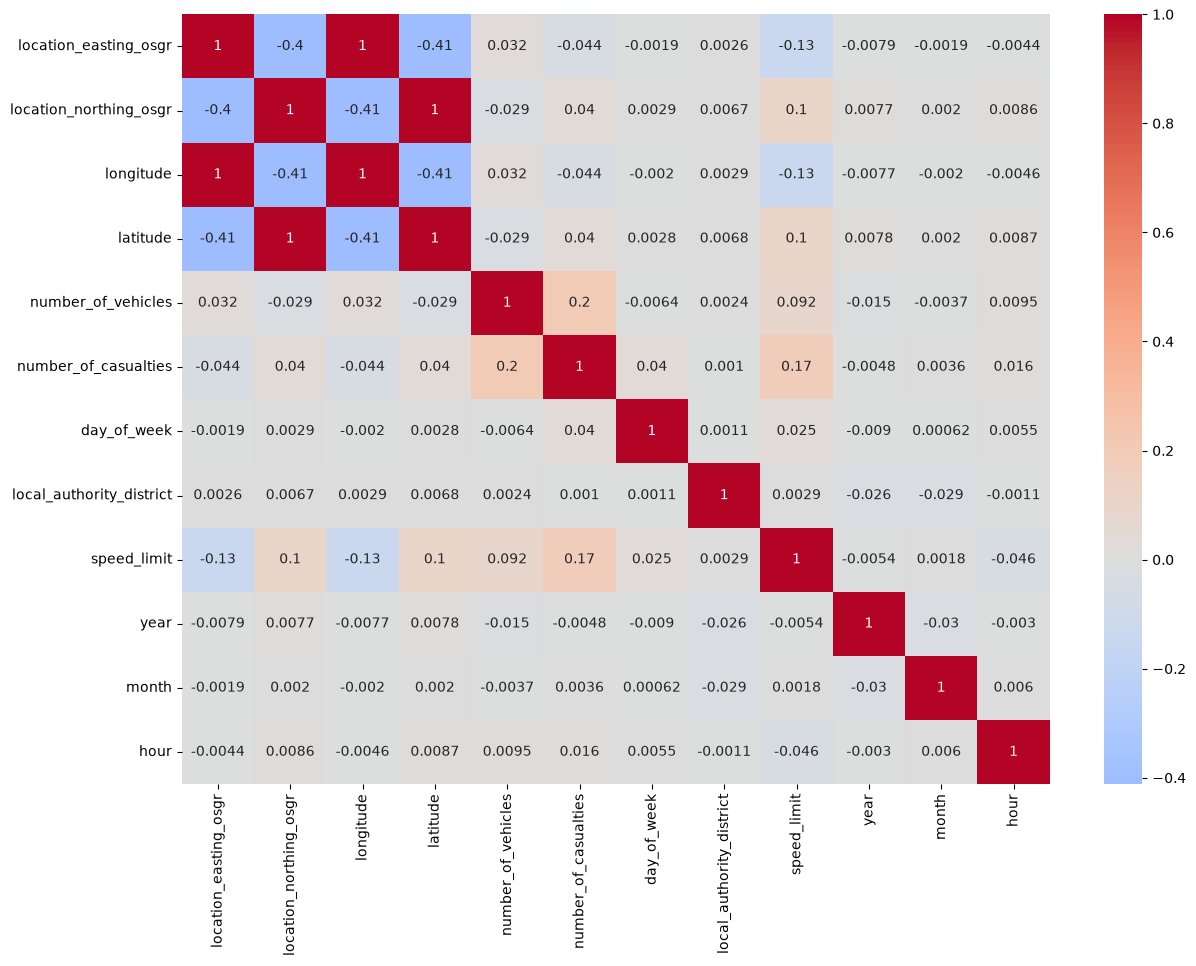

In [172]:
import seaborn as sns
import matplotlib.pyplot as plt

corr = X[num_cols].corr()

plt.figure(figsize=(14, 10))
sns.heatmap(corr,annot=True, cmap="coolwarm", center=0)
plt.show()

In [173]:
print(X[[
    "location_easting_osgr", "longitude",
    "location_northing_osgr", "latitude"
]].corr())

                        location_easting_osgr  longitude  \
location_easting_osgr                1.000000   0.999468   
longitude                            0.999468   1.000000   
location_northing_osgr              -0.402415  -0.409404   
latitude                            -0.405116  -0.412028   

                        location_northing_osgr  latitude  
location_easting_osgr                -0.402415 -0.405116  
longitude                            -0.409404 -0.412028  
location_northing_osgr                1.000000  0.999968  
latitude                              0.999968  1.000000  


In [174]:
X = X.drop(columns=[
    "location_easting_osgr",
    "location_northing_osgr"
])

print("Shape:", X.shape)

Shape: (513748, 32)


In [175]:
print(X[cat_cols].dtypes)

police_force                                          int64
first_road_class                                      int64
road_type                                             int64
junction_detail_historic                              int64
junction_detail                                       int64
junction_control                                      int64
second_road_class                                     int64
pedestrian_crossing_human_control_historic            int64
pedestrian_crossing_physical_facilities_historic      int64
pedestrian_crossing                                   int64
light_conditions                                    float64
weather_conditions                                  float64
road_surface_conditions                             float64
urban_or_rural_area                                   int64
did_police_officer_attend_scene_of_accident           int64
trunk_road_flag                                       int64
local_authority_ons_district            

In [176]:
str_cols = X.select_dtypes(include="str").columns.tolist()
print(X[str_cols].nunique().sort_values(ascending=False))

lsoa_of_accident_location          35630
local_authority_ons_district         370
local_authority_highway_current      207
carriageway_hazards                   14
special_conditions_at_site            10
carriageway_hazards_historic           8
dtype: int64


In [177]:
geo_cols = [
    "lsoa_of_accident_location",
    "local_authority_ons_district",
    "local_authority_highway_current"
]
X_with_geo = X.copy()
X_without_geo = X.drop(columns=geo_cols)
print("With geographical features:", X_with_geo.shape)
print("Without geographical features:", X_without_geo.shape)

With geographical features: (513748, 32)
Without geographical features: (513748, 29)


In [178]:
print(y.value_counts().sort_index())
print(y.isnull().sum())

collision_severity
1      7552
2    116797
3    389399
Name: count, dtype: int64
0


In [179]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_with_geo,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape, X_test.shape)
print(y_train.value_counts(normalize=True) * 100)
print(y_test.value_counts(normalize=True) * 100)

(410998, 32) (102750, 32)
collision_severity
3    75.795746
2    22.734174
1     1.470080
Name: proportion, dtype: float64
collision_severity
3    75.795620
2    22.734793
1     1.469586
Name: proportion, dtype: float64


In [180]:
print("Categorical:", len(cat_cols))
print("Numerical:", len(num_cols))
print("Training shape:", X_train.shape)

Categorical: 22
Numerical: 12
Training shape: (410998, 32)


In [181]:
cat_cols = [col for col in cat_cols if col in X_train.columns]

print(len(cat_cols))
print(cat_cols)

22
['police_force', 'first_road_class', 'road_type', 'junction_detail_historic', 'junction_detail', 'junction_control', 'second_road_class', 'pedestrian_crossing_human_control_historic', 'pedestrian_crossing_physical_facilities_historic', 'pedestrian_crossing', 'light_conditions', 'weather_conditions', 'road_surface_conditions', 'urban_or_rural_area', 'did_police_officer_attend_scene_of_accident', 'trunk_road_flag', 'local_authority_ons_district', 'local_authority_highway_current', 'special_conditions_at_site', 'carriageway_hazards_historic', 'carriageway_hazards', 'lsoa_of_accident_location']


In [182]:
X_train[cat_cols].nunique().sort_values(ascending=False)

lsoa_of_accident_location                           35124
local_authority_ons_district                          370
local_authority_highway_current                       207
police_force                                           44
carriageway_hazards                                    14
junction_detail_historic                               11
pedestrian_crossing                                    10
special_conditions_at_site                             10
weather_conditions                                      9
second_road_class                                       9
pedestrian_crossing_physical_facilities_historic        8
carriageway_hazards_historic                            8
junction_detail                                         8
first_road_class                                        7
junction_control                                        6
road_type                                               6
road_surface_conditions                                 6
pedestrian_cro

In [183]:
high_card_cols = [
    "lsoa_of_accident_location",
    "local_authority_ons_district",
    "local_authority_highway_current",
    "police_force"
]

low_card_cols = [
    col for col in cat_cols
    if col not in high_card_cols
]

print("High cardinality:", len(high_card_cols))
print("Low cardinality:", len(low_card_cols))

High cardinality: 4
Low cardinality: 18


In [184]:
X_train[high_card_cols].nunique()

lsoa_of_accident_location          35124
local_authority_ons_district         370
local_authority_highway_current      207
police_force                          44
dtype: int64

In [185]:
X_train["lsoa_of_accident_location"].value_counts().describe()

count    35124.000000
mean        11.701344
std         88.579845
min          1.000000
25%          4.000000
50%          7.000000
75%         14.000000
max      16440.000000
Name: count, dtype: float64

In [186]:
X_train[
    ["local_authority_ons_district",
     "local_authority_highway_current"]
].apply(lambda col: col.value_counts().describe())

,local_authority_ons_district,local_authority_highway_current
count,370.000000,207.000000
mean,1110.805405,1985.497585
std,986.893654,1974.544153
min,7.000000,7.000000
25%,533.750000,679.500000
50%,810.000000,1411.000000
75%,1299.250000,2699.000000
max,9011.000000,12796.000000


In [187]:
num_cols = [
    col for col in X_train.select_dtypes(include="number").columns
    if col not in cat_cols
]

print("Categorical:", len(cat_cols))
print("Numerical:", len(num_cols))
print("Total:", len(cat_cols) + len(num_cols))
print(num_cols)

Categorical: 22
Numerical: 10
Total: 32
['longitude', 'latitude', 'number_of_vehicles', 'number_of_casualties', 'day_of_week', 'local_authority_district', 'speed_limit', 'year', 'month', 'hour']


In [188]:
cat_indices = [
    X_train.columns.get_loc(col)
    for col in cat_cols
]

print("Categorical feature indices:", cat_indices)
print("Number of categorical indices:", len(cat_indices))

Categorical feature indices: [2, 9, 10, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 25, 26, 27, 7, 8, 22, 23, 24, 28]
Number of categorical indices: 22


In [189]:
str_cols = X_train.select_dtypes(include="str").columns.tolist()

print("String columns:", len(str_cols))
print(str_cols)

String columns: 6
['local_authority_ons_district', 'local_authority_highway_current', 'special_conditions_at_site', 'carriageway_hazards_historic', 'carriageway_hazards', 'lsoa_of_accident_location']


In [190]:
from sklearn.preprocessing import OrdinalEncoder

In [191]:
encoder = OrdinalEncoder(
    handle_unknown="use_encoded_value",
    unknown_value=-1
)

X_train[str_cols] = encoder.fit_transform(X_train[str_cols])
X_test[str_cols] = encoder.transform(X_test[str_cols])

In [192]:
print("Training data types:")
print(X_train[str_cols].dtypes)

print("\nSample encoded values:")
print(X_train[str_cols].head())

print("\nMissing values:")
print(X_train[str_cols].isnull().sum().sum())

Training data types:
local_authority_ons_district       float64
local_authority_highway_current    float64
special_conditions_at_site         float64
carriageway_hazards_historic       float64
carriageway_hazards                float64
lsoa_of_accident_location          float64
dtype: object

Sample encoded values:
        local_authority_ons_district  local_authority_highway_current  \
13833                          346.0                            183.0   
269727                         312.0                            129.0   
22472                          314.0                            131.0   
165904                         296.0                            113.0   
306592                          25.0                             25.0   

        special_conditions_at_site  carriageway_hazards_historic  \
13833                          2.0                           3.0   
269727                         4.0                           4.0   
22472                          2.0      

In [193]:
print(num_cols)

['longitude', 'latitude', 'number_of_vehicles', 'number_of_casualties', 'day_of_week', 'local_authority_district', 'speed_limit', 'year', 'month', 'hour']


In [194]:
additional_cat_cols = [
    "day_of_week",
    "local_authority_district",
    "year",
    "month",
    "hour"
]

In [195]:
cat_cols = cat_cols + additional_cat_cols

cat_indices = [
    X_train.columns.get_loc(col)
    for col in cat_cols
]

print("Categorical features:", len(cat_cols))
print("Categorical indices:", len(cat_indices))

Categorical features: 27
Categorical indices: 27


In [196]:
print("Duplicate categorical columns:", 
      len(cat_cols) - len(set(cat_cols)))

Duplicate categorical columns: 0


In [197]:
num_cols = [
    col for col in X_train.select_dtypes(include="number").columns
    if col not in cat_cols
]

print("Numerical features:", len(num_cols))
print(num_cols)

Numerical features: 5
['longitude', 'latitude', 'number_of_vehicles', 'number_of_casualties', 'speed_limit']


In [198]:
try:
    import catboost
    print("CatBoost is installed:", catboost.__version__)
except ImportError:
    print("CatBoost is not installed")

CatBoost is installed: 1.2.10


In [199]:
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("Categorical features:", len(cat_cols))
print("All geographical features present:",
      all(col in X_train.columns for col in high_card_cols))

Training shape: (410998, 32)
Testing shape: (102750, 32)
Categorical features: 27
All geographical features present: True


In [200]:
print(X_train.shape, X_test.shape)
print(len(cat_cols), len(num_cols))

(410998, 32) (102750, 32)
27 5


In [201]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler

In [202]:
geo_cols = high_card_cols

low_cat_cols = [
    col for col in cat_cols
    if col not in geo_cols
]

print("Geographical features:", len(geo_cols))
print("Other categorical features:", len(low_cat_cols))
print("Numerical features:", len(num_cols))

Geographical features: 4
Other categorical features: 23
Numerical features: 5


In [203]:
class FrequencyEncoder(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        X = pd.DataFrame(X).copy()
        self.feature_names_in_ = X.columns
        self.frequency_maps_ = {}
        for col in X.columns:
            values = X[col].astype("string").fillna("__MISSING__")
            self.frequency_maps_[col] = (
                values.value_counts(normalize=True).to_dict()
            )
        return self
    def transform(self, X):
        X = pd.DataFrame(
            X,
            columns=self.feature_names_in_
        ).copy()
        encoded = pd.DataFrame(index=X.index)
        for col in X.columns:
            values = X[col].astype("string").fillna("__MISSING__")
            encoded[col] = values.map(
                self.frequency_maps_[col]
            ).fillna(0)
        return encoded.to_numpy()

In [204]:
def create_preprocessor(scale_numeric=True):

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median"))
    ])
    if scale_numeric:
        numeric_pipeline.steps.append(
            ("scaler", StandardScaler())
        )

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(
            handle_unknown="ignore",
            min_frequency=20
        ))
    ])

    geo_pipeline = Pipeline([
        ("frequency", FrequencyEncoder())
    ])

    preprocessor = ColumnTransformer([
        ("numeric", numeric_pipeline, num_cols),
        ("categorical", categorical_pipeline, low_cat_cols),
        ("geographical", geo_pipeline, geo_cols)
    ])

    return preprocessor

In [205]:
logistic_model = Pipeline([
    ("preprocessor", create_preprocessor(scale_numeric=True)),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=200,
        solver="lbfgs",
        random_state=42
    ))
])

In [206]:
knn_model = ImbPipeline([
    ("preprocessor", create_preprocessor(scale_numeric=True)),
    ("sampler", RandomUnderSampler(
        sampling_strategy="not minority",
        random_state=42
    )),
    ("classifier", KNeighborsClassifier(
        n_neighbors=5,
        weights="distance",
        n_jobs=-1
    ))
])

In [207]:
rf_model = Pipeline([
    ("preprocessor", create_preprocessor(scale_numeric=False)),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=5,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

In [208]:
X_test_eval, _, y_test_eval, _ = train_test_split(
    X_test,
    y_test,
    train_size=10000,
    stratify=y_test,
    random_state=42
)

print(X_test_eval.shape)
print(y_test_eval.value_counts(normalize=True))

(10000, 32)
collision_severity
3    0.7580
2    0.2273
1    0.0147
Name: proportion, dtype: float64


In [209]:
X_train_sample, _, y_train_sample, _ = train_test_split(
    X_train,
    y_train,
    train_size=100000,
    stratify=y_train,
    random_state=42
)

print("Training sample:", X_train_sample.shape)
print(y_train_sample.value_counts())

Training sample: (100000, 32)
collision_severity
3    75796
2    22734
1     1470
Name: count, dtype: int64


In [210]:
models = {
    "Logistic Regression": logistic_model,
    "KNN": knn_model,
    "Random Forest": rf_model
}

for name, model in models.items():

    print(f"\nTraining {name}...")

    model.fit(X_train_sample, y_train_sample)

    print(f"{name} training completed!")


Training Logistic Regression...


C:\Users\BANAPURAM VINAY TEJA\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 200 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=200).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Logistic Regression training completed!

Training KNN...
KNN training completed!

Training Random Forest...
Random Forest training completed!


In [211]:
results = {}

for name, model in models.items():

    print(f"\n{'='*50}")
    print(name)
    print('='*50)

    predictions = model.predict(X_test_eval)

    accuracy = accuracy_score(y_test_eval, predictions)

    macro_f1 = f1_score(
        y_test_eval,
        predictions,
        average="macro"
    )

    weighted_f1 = f1_score(
        y_test_eval,
        predictions,
        average="weighted"
    )

    results[name] = {
        "Accuracy": accuracy,
        "Macro F1": macro_f1,
        "Weighted F1": weighted_f1
    }

    print("Accuracy:", accuracy)
    print("Macro F1:", macro_f1)
    print("Weighted F1:", weighted_f1)

    print("\nClassification Report:")

    print(classification_report(
        y_test_eval,
        predictions,
        labels=[1, 2, 3],
        target_names=["Fatal", "Serious", "Slight"],
        zero_division=0
    ))


Logistic Regression
Accuracy: 0.4845
Macro F1: 0.3431161994430842
Weighted F1: 0.5609810815725372

Classification Report:
              precision    recall  f1-score   support

       Fatal       0.03      0.57      0.07       147
     Serious       0.28      0.37      0.32      2273
      Slight       0.85      0.52      0.64      7580

    accuracy                           0.48     10000
   macro avg       0.39      0.49      0.34     10000
weighted avg       0.71      0.48      0.56     10000


KNN
Accuracy: 0.4185
Macro F1: 0.3040480828666197
Weighted F1: 0.49566911733865615

Classification Report:
              precision    recall  f1-score   support

       Fatal       0.03      0.51      0.06       147
     Serious       0.24      0.37      0.29      2273
      Slight       0.82      0.43      0.57      7580

    accuracy                           0.42     10000
   macro avg       0.36      0.44      0.30     10000
weighted avg       0.67      0.42      0.50     10000


Random

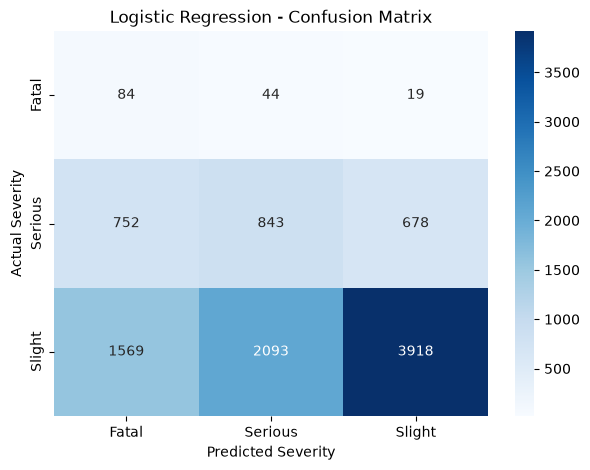

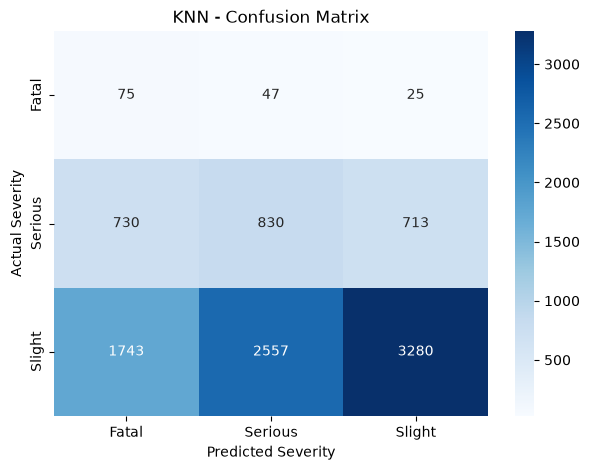

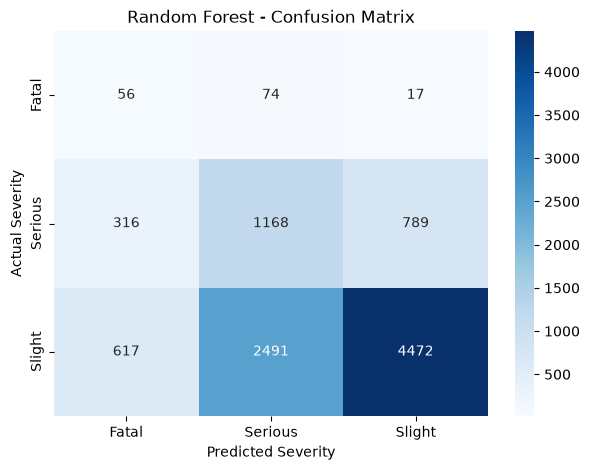

In [212]:
for name, model in models.items():

    predictions = model.predict(X_test_eval)

    cm = confusion_matrix(
        y_test_eval,
        predictions,
        labels=[1, 2, 3]
    )

    plt.figure(figsize=(7, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Fatal", "Serious", "Slight"],
        yticklabels=["Fatal", "Serious", "Slight"]
    )

    plt.title(f"{name} - Confusion Matrix")
    plt.xlabel("Predicted Severity")
    plt.ylabel("Actual Severity")
    plt.show()

In [213]:
logistic_model = Pipeline([
    ("preprocessor", create_preprocessor(scale_numeric=True)),

    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        solver="lbfgs",
        C=1.0,
        random_state=42
    ))
])

In [214]:
logistic_model.fit(X_train_sample, y_train_sample)
print("Improved Logistic Regression training completed!")

Improved Logistic Regression training completed!


In [215]:
lr_predictions = logistic_model.predict(X_test_eval)

print(classification_report(
    y_test_eval,
    lr_predictions,
    labels=[1, 2, 3],
    target_names=["Fatal", "Serious", "Slight"],
    zero_division=0
))

print("Macro F1:", f1_score(
    y_test_eval,
    lr_predictions,
    average="macro"
))

              precision    recall  f1-score   support

       Fatal       0.04      0.57      0.07       147
     Serious       0.28      0.37      0.32      2273
      Slight       0.85      0.52      0.64      7580

    accuracy                           0.48     10000
   macro avg       0.39      0.49      0.34     10000
weighted avg       0.71      0.48      0.56     10000

Macro F1: 0.3432912592829749


In [216]:
from sklearn.base import clone

C_values = [0.01, 0.1, 1, 10]

lr_results = []

for c in C_values:

    model = clone(logistic_model)

    model.set_params(classifier__C=c)

    model.fit(X_train_sample, y_train_sample)

    predictions = model.predict(X_test_eval)

    score = f1_score(
        y_test_eval,
        predictions,
        average="macro"
    )

    lr_results.append({
        "C": c,
        "Macro F1": score
    })

    print(f"C = {c}, Macro F1 = {score:.4f}")

lr_results_df = pd.DataFrame(lr_results)

display(lr_results_df)

C = 0.01, Macro F1 = 0.3439
C = 0.1, Macro F1 = 0.3429
C = 1, Macro F1 = 0.3433
C = 10, Macro F1 = 0.3434


,C,Macro F1
0,0.01,0.343874
1,0.10,0.342925
2,1.00,0.343291
3,10.00,0.343368


In [217]:
from sklearn.base import clone

k_values = [3, 5, 7, 9, 11]

knn_results = []

for k in k_values:

    model = clone(knn_model)

    model.set_params(
        classifier__n_neighbors=k
    )

    model.fit(X_train_sample, y_train_sample)

    predictions = model.predict(X_test_eval)

    score = f1_score(
        y_test_eval,
        predictions,
        average="macro"
    )

    knn_results.append({
        "K": k,
        "Macro F1": score
    })

    print(f"K = {k}, Macro F1 = {score:.4f}")

knn_results_df = pd.DataFrame(knn_results)

display(knn_results_df)

K = 3, Macro F1 = 0.2968
K = 5, Macro F1 = 0.3040
K = 7, Macro F1 = 0.3037
K = 9, Macro F1 = 0.3055
K = 11, Macro F1 = 0.3059


,K,Macro F1
0,3,0.296796
1,5,0.304048
2,7,0.303689
3,9,0.305517
4,11,0.305884


In [218]:
from sklearn.base import clone

rf_results = []

rf_params = [
    (100, 10),
    (100, 15),
    (200, 15),
    (200, 20),
    (300, 20)
]

for trees, depth in rf_params:

    model = clone(rf_model)

    model.set_params(
        classifier__n_estimators=trees,
        classifier__max_depth=depth
    )

    model.fit(X_train_sample, y_train_sample)

    predictions = model.predict(X_test_eval)

    score = f1_score(
        y_test_eval,
        predictions,
        average="macro"
    )

    rf_results.append({
        "Trees": trees,
        "Max Depth": depth,
        "Macro F1": score
    })

    print(
        f"Trees={trees}, Depth={depth}, "
        f"Macro F1={score:.4f}"
    )

rf_results_df = pd.DataFrame(rf_results)

display(rf_results_df)

Trees=100, Depth=10, Macro F1=0.3616
Trees=100, Depth=15, Macro F1=0.3944
Trees=200, Depth=15, Macro F1=0.3949
Trees=200, Depth=20, Macro F1=0.4178
Trees=300, Depth=20, Macro F1=0.4191


,Trees,Max Depth,Macro F1
0,100,10,0.361642
1,100,15,0.394378
2,200,15,0.394923
3,200,20,0.417757
4,300,20,0.419147


In [219]:
from sklearn.base import clone

leaf_results = []

for leaf in [1, 2, 5, 10]:

    model = clone(rf_model)

    model.set_params(
        classifier__n_estimators=300,
        classifier__max_depth=20,
        classifier__min_samples_leaf=leaf
    )

    model.fit(X_train_sample, y_train_sample)

    predictions = model.predict(X_test_eval)

    score = f1_score(
        y_test_eval,
        predictions,
        average="macro"
    )

    leaf_results.append({
        "Min Samples Leaf": leaf,
        "Macro F1": score
    })

    print(f"Leaf={leaf}, Macro F1={score:.4f}")

leaf_results_df = pd.DataFrame(leaf_results)

display(leaf_results_df)

Leaf=1, Macro F1=0.4054
Leaf=2, Macro F1=0.4193
Leaf=5, Macro F1=0.4191
Leaf=10, Macro F1=0.4074


,Min Samples Leaf,Macro F1
0,1,0.405424
1,2,0.419272
2,5,0.419147
3,10,0.407436


In [220]:
best_rf_model = Pipeline([
    ("preprocessor", create_preprocessor(scale_numeric=False)),

    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=20,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

In [221]:
best_rf_model.fit(X_train_sample, y_train_sample)
print("Tuned Random Forest training completed!")

Tuned Random Forest training completed!


In [222]:
rf_predictions = best_rf_model.predict(X_test_eval)

print(classification_report(
    y_test_eval,
    rf_predictions,
    labels=[1, 2, 3],
    target_names=["Fatal", "Serious", "Slight"],
    zero_division=0
))

print("Macro F1:", f1_score(
    y_test_eval,
    rf_predictions,
    average="macro"
))

              precision    recall  f1-score   support

       Fatal       0.08      0.15      0.10       147
     Serious       0.35      0.37      0.36      2273
      Slight       0.81      0.78      0.79      7580

    accuracy                           0.68     10000
   macro avg       0.41      0.43      0.42     10000
weighted avg       0.69      0.68      0.69     10000

Macro F1: 0.41927227067374667


In [223]:
X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_train_sample,
    y_train_sample,
    test_size=0.2,
    stratify=y_train_sample,
    random_state=42
)

print("Training:", X_train_final.shape)
print("Validation:", X_val.shape)

print("\nValidation class distribution:")
print(y_val.value_counts(normalize=True))

Training: (80000, 32)
Validation: (20000, 32)

Validation class distribution:
collision_severity
3    0.75795
2    0.22735
1    0.01470
Name: proportion, dtype: float64


In [224]:
final_lr = Pipeline([
    ("preprocessor", create_preprocessor(scale_numeric=True)),
    ("classifier", LogisticRegression(
        C=0.01,
        class_weight="balanced",
        max_iter=1000,
        solver="lbfgs",
        random_state=42
    ))
])

In [225]:
final_knn = ImbPipeline([
    ("preprocessor", create_preprocessor(scale_numeric=True)),
    ("sampler", RandomUnderSampler(
        sampling_strategy="not minority",
        random_state=42
    )),
    ("classifier", KNeighborsClassifier(
        n_neighbors=11,
        weights="distance",
        n_jobs=-1
    ))
])

In [226]:
final_rf = Pipeline([
    ("preprocessor", create_preprocessor(scale_numeric=False)),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=20,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

In [227]:
final_models = {
    "Logistic Regression": final_lr,
    "KNN": final_knn,
    "Random Forest": final_rf
}

for name, model in final_models.items():

    print(f"\nTraining {name}...")

    model.fit(X_train_final, y_train_final)

    print(f"{name} completed!")


Training Logistic Regression...
Logistic Regression completed!

Training KNN...
KNN completed!

Training Random Forest...
Random Forest completed!


In [228]:
validation_results = {}

for name, model in final_models.items():

    print(f"\n{'='*50}")
    print(name)
    print('='*50)

    predictions = model.predict(X_val)

    accuracy = accuracy_score(y_val, predictions)

    macro_f1 = f1_score(
        y_val,
        predictions,
        average="macro"
    )

    weighted_f1 = f1_score(
        y_val,
        predictions,
        average="weighted"
    )

    validation_results[name] = {
        "Accuracy": accuracy,
        "Macro F1": macro_f1,
        "Weighted F1": weighted_f1
    }

    print("Accuracy:", accuracy)
    print("Macro F1:", macro_f1)
    print("Weighted F1:", weighted_f1)

    print("\nClassification Report:")

    print(classification_report(
        y_val,
        predictions,
        labels=[1, 2, 3],
        target_names=["Fatal", "Serious", "Slight"],
        zero_division=0
    ))


Logistic Regression
Accuracy: 0.48725
Macro F1: 0.34796647836989986
Weighted F1: 0.563076377126882

Classification Report:
              precision    recall  f1-score   support

       Fatal       0.04      0.65      0.07       294
     Serious       0.29      0.38      0.33      4547
      Slight       0.85      0.52      0.64     15159

    accuracy                           0.49     20000
   macro avg       0.39      0.51      0.35     20000
weighted avg       0.71      0.49      0.56     20000


KNN
Accuracy: 0.42795
Macro F1: 0.3127763183619077
Weighted F1: 0.5086847891659932

Classification Report:
              precision    recall  f1-score   support

       Fatal       0.03      0.64      0.06       294
     Serious       0.25      0.35      0.29      4547
      Slight       0.83      0.45      0.58     15159

    accuracy                           0.43     20000
   macro avg       0.37      0.48      0.31     20000
weighted avg       0.69      0.43      0.51     20000


Rando

In [229]:
validation_df = pd.DataFrame(validation_results).T

display(validation_df)

,Accuracy,Macro F1,Weighted F1
Logistic Regression,0.48725,0.347966,0.563076
KNN,0.42795,0.312776,0.508685
Random Forest,0.68480,0.420177,0.689080


In [230]:
for name, model in final_models.items():

    predictions = model.predict(X_val)

    report = classification_report(
        y_val,
        predictions,
        labels=[1, 2, 3],
        output_dict=True,
        zero_division=0
    )

    print(
        name,
        "Fatal Recall:",
        round(report["1"]["recall"], 4)
    )

Logistic Regression Fatal Recall: 0.6497
KNN Fatal Recall: 0.6395
Random Forest Fatal Recall: 0.1259


In [231]:
fatal_comparison = []

for name, model in final_models.items():

    predictions = model.predict(X_val)

    report = classification_report(
        y_val,
        predictions,
        labels=[1, 2, 3],
        output_dict=True,
        zero_division=0
    )

    fatal_comparison.append({
        "Model": name,
        "Fatal Precision": report["1"]["precision"],
        "Fatal Recall": report["1"]["recall"],
        "Fatal F1": report["1"]["f1-score"]
    })

fatal_df = pd.DataFrame(fatal_comparison)

display(fatal_df)

,Model,Fatal Precision,Fatal Recall,Fatal F1
0,Logistic Regression,0.039504,0.649660,0.074478
1,KNN,0.033892,0.639456,0.064373
2,Random Forest,0.083710,0.125850,0.100543


In [232]:
lr_probabilities = final_lr.predict_proba(X_val)

print("Class order:", final_lr.classes_)
print("Probability shape:", lr_probabilities.shape)

fatal_index = list(final_lr.classes_).index(1)

fatal_probabilities = lr_probabilities[:, fatal_index]

print("\nFirst 10 Fatal probabilities:")
print(fatal_probabilities[:10])

Class order: [1 2 3]
Probability shape: (20000, 3)

First 10 Fatal probabilities:
[0.00742814 0.21850926 0.48140642 0.57161566 0.29322449 0.30411043
 0.14913025 0.19342496 0.44666588 0.17278467]


In [233]:
thresholds = [0.10, 0.15, 0.20, 0.25, 0.30, 0.35]

threshold_results = []

for threshold in thresholds:

    predictions = np.argmax(lr_probabilities, axis=1) + 1

    fatal_mask = fatal_probabilities >= threshold

    predictions[fatal_mask] = 1

    report = classification_report(
        y_val,
        predictions,
        labels=[1, 2, 3],
        output_dict=True,
        zero_division=0
    )

    threshold_results.append({
        "Threshold": threshold,
        "Fatal Precision": report["1"]["precision"],
        "Fatal Recall": report["1"]["recall"],
        "Fatal F1": report["1"]["f1-score"],
        "Macro F1": report["macro avg"]["f1-score"]
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df)

,Threshold,Fatal Precision,Fatal Recall,Fatal F1,Macro F1
0,0.10,0.020500,0.986395,0.040166,0.180593
1,0.15,0.022742,0.952381,0.044423,0.216756
2,0.20,0.025631,0.904762,0.049850,0.259840
3,0.25,0.028924,0.829932,0.055899,0.295724
4,0.30,0.033991,0.778912,0.065140,0.323683
5,0.35,0.037498,0.687075,0.071114,0.339633


In [234]:
best_threshold = 0.35

threshold_predictions = np.argmax(
    lr_probabilities, axis=1
) + 1

fatal_mask = fatal_probabilities >= best_threshold

threshold_predictions[fatal_mask] = 1

print(classification_report(
    y_val,
    threshold_predictions,
    labels=[1, 2, 3],
    target_names=["Fatal", "Serious", "Slight"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(
    y_val,
    threshold_predictions,
    labels=[1, 2, 3]
))

              precision    recall  f1-score   support

       Fatal       0.04      0.69      0.07       294
     Serious       0.28      0.34      0.31      4547
      Slight       0.85      0.52      0.64     15159

    accuracy                           0.48     20000
   macro avg       0.39      0.51      0.34     20000
weighted avg       0.71      0.48      0.56     20000

Confusion Matrix:
[[ 202   62   30]
 [1694 1526 1327]
 [3491 3855 7813]]


In [235]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler

ros_lr = ImbPipeline([
    ("preprocessor", create_preprocessor(scale_numeric=True)),
    ("sampler", RandomOverSampler(random_state=42)),
    ("classifier", LogisticRegression(
        C=0.01,
        max_iter=1000,
        solver="lbfgs",
        random_state=42
    ))
])

ros_lr.fit(X_train_final, y_train_final)

print("Logistic Regression with RandomOverSampler trained!")

Logistic Regression with RandomOverSampler trained!


In [236]:
ros_predictions = ros_lr.predict(X_val)

print("Classification Report:\n")

print(classification_report(
    y_val,
    ros_predictions,
    labels=[1, 2, 3],
    target_names=["Fatal", "Serious", "Slight"],
    zero_division=0
))

print("Confusion Matrix:\n")

print(confusion_matrix(
    y_val,
    ros_predictions,
    labels=[1, 2, 3]
))

print("Macro F1:",
      f1_score(y_val, ros_predictions, average="macro"))

Classification Report:

              precision    recall  f1-score   support

       Fatal       0.04      0.65      0.07       294
     Serious       0.29      0.38      0.33      4547
      Slight       0.85      0.52      0.64     15159

    accuracy                           0.49     20000
   macro avg       0.39      0.51      0.35     20000
weighted avg       0.71      0.49      0.56     20000

Confusion Matrix:

[[ 191   74   29]
 [1496 1716 1335]
 [3162 4149 7848]]
Macro F1: 0.3485377998782058


In [237]:
rf_weighted = Pipeline([
    ("preprocessor", create_preprocessor(scale_numeric=False)),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=20,
        min_samples_leaf=2,
        class_weight={
            1: 10,
            2: 2,
            3: 1
        },
        random_state=42,
        n_jobs=-1
    ))
])

rf_weighted.fit(X_train_final, y_train_final)

print("Weighted Random Forest trained!")

Weighted Random Forest trained!


In [238]:
rf_weighted_predictions = rf_weighted.predict(X_val)

print("Classification Report:\n")

print(classification_report(
    y_val,
    rf_weighted_predictions,
    labels=[1, 2, 3],
    target_names=["Fatal", "Serious", "Slight"],
    zero_division=0
))

print("Confusion Matrix:\n")

print(confusion_matrix(
    y_val,
    rf_weighted_predictions,
    labels=[1, 2, 3]
))

print("Macro F1:",
      f1_score(
          y_val,
          rf_weighted_predictions,
          average="macro"
      ))

Classification Report:

              precision    recall  f1-score   support

       Fatal       0.20      0.01      0.03       294
     Serious       0.42      0.19      0.26      4547
      Slight       0.78      0.93      0.85     15159

    accuracy                           0.75     20000
   macro avg       0.47      0.38      0.38     20000
weighted avg       0.69      0.75      0.70     20000

Confusion Matrix:

[[    4   100   190]
 [    9   850  3688]
 [    7  1059 14093]]
Macro F1: 0.37851728536068396


In [239]:
rf_weighted_mild = Pipeline([
    ("preprocessor", create_preprocessor(scale_numeric=False)),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=20,
        min_samples_leaf=2,
        class_weight={1: 3, 2: 1.5, 3: 1},
        random_state=42,
        n_jobs=-1
    ))
])

rf_weighted_mild.fit(X_train_final, y_train_final)

print("Mildly weighted Random Forest trained!")

Mildly weighted Random Forest trained!


In [240]:
rf_mild_predictions = rf_weighted_mild.predict(X_val)

print("Classification Report:\n")

print(classification_report(
    y_val,
    rf_mild_predictions,
    labels=[1, 2, 3],
    target_names=["Fatal", "Serious", "Slight"],
    zero_division=0
))

print("Confusion Matrix:\n")

print(confusion_matrix(
    y_val,
    rf_mild_predictions,
    labels=[1, 2, 3]
))

print("Macro F1:",
      f1_score(
          y_val,
          rf_mild_predictions,
          average="macro"
      ))

Classification Report:

              precision    recall  f1-score   support

       Fatal       0.00      0.00      0.00       294
     Serious       0.45      0.07      0.12      4547
      Slight       0.77      0.98      0.86     15159

    accuracy                           0.76     20000
   macro avg       0.41      0.35      0.33     20000
weighted avg       0.68      0.76      0.68     20000

Confusion Matrix:

[[    0    55   239]
 [    0   307  4240]
 [    0   318 14841]]
Macro F1: 0.3261129444360631


In [241]:
final_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "KNN",
        "Random Forest"
    ],
    "Accuracy": [
        0.48725,
        0.42795,
        0.68480
    ],
    "Macro F1": [
        0.34797,
        0.31278,
        0.42018
    ],
    "Fatal Recall": [
        0.64966,
        0.63946,
        0.12585
    ]
})

display(
    final_comparison.sort_values(
        by="Macro F1",
        ascending=False
    )
)

,Model,Accuracy,Macro F1,Fatal Recall
2,Random Forest,0.68480,0.42018,0.12585
0,Logistic Regression,0.48725,0.34797,0.64966
1,KNN,0.42795,0.31278,0.63946


In [242]:
best_model = final_models["Random Forest"]

final_predictions = best_model.predict(X_test)

print("FINAL RANDOM FOREST EVALUATION\n")

print(classification_report(
    y_test,
    final_predictions,
    labels=[1, 2, 3],
    target_names=["Fatal", "Serious", "Slight"],
    zero_division=0
))

print("Macro F1:",
      f1_score(y_test, final_predictions, average="macro"))

print("Confusion Matrix:\n",
      confusion_matrix(y_test, final_predictions, labels=[1, 2, 3]))

FINAL RANDOM FOREST EVALUATION

              precision    recall  f1-score   support

       Fatal       0.07      0.11      0.09      1510
     Serious       0.36      0.36      0.36     23360
      Slight       0.81      0.80      0.80     77880

    accuracy                           0.69    102750
   macro avg       0.41      0.42      0.42    102750
weighted avg       0.69      0.69      0.69    102750

Macro F1: 0.41589636654254813
Confusion Matrix:
 [[  165   709   636]
 [  765  8430 14165]
 [ 1321 14558 62001]]


In [243]:
print("Number of features:", len(X_train_final.columns))
print("\nFeature names:")
print(X_train_final.columns.tolist())

Number of features: 32

Feature names:
['longitude', 'latitude', 'police_force', 'number_of_vehicles', 'number_of_casualties', 'day_of_week', 'local_authority_district', 'local_authority_ons_district', 'local_authority_highway_current', 'first_road_class', 'road_type', 'speed_limit', 'junction_detail_historic', 'junction_detail', 'junction_control', 'second_road_class', 'pedestrian_crossing_human_control_historic', 'pedestrian_crossing_physical_facilities_historic', 'pedestrian_crossing', 'light_conditions', 'weather_conditions', 'road_surface_conditions', 'special_conditions_at_site', 'carriageway_hazards_historic', 'carriageway_hazards', 'urban_or_rural_area', 'did_police_officer_attend_scene_of_accident', 'trunk_road_flag', 'lsoa_of_accident_location', 'year', 'month', 'hour']


In [244]:
sample_input = X_test.iloc[[0]]

print("Input shape:", sample_input.shape)
display(sample_input)

Input shape: (1, 32)


,longitude,latitude,police_force,number_of_vehicles,number_of_casualties,day_of_week,local_authority_district,local_authority_ons_district,local_authority_highway_current,first_road_class,...,special_conditions_at_site,carriageway_hazards_historic,carriageway_hazards,urban_or_rural_area,did_police_officer_attend_scene_of_accident,trunk_road_flag,lsoa_of_accident_location,year,month,hour
14244,0.47329,51.57113,42,1,1,0,-1,95.0,136.0,6,...,2.0,3.0,7.0,1,3,2,20062.0,2024,10,15


In [245]:
final_prediction = final_rf.predict(sample_input)

severity_labels = {
    1: "Fatal",
    2: "Serious",
    3: "Slight"
}

predicted_severity = severity_labels[int(final_prediction[0])]

print("Predicted Collision Severity:", predicted_severity)

Predicted Collision Severity: Slight


In [246]:
import os

print(os.getcwd())

C:\Users\BANAPURAM VINAY TEJA
